In [1]:
import sys
import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib
import joblib

print("Python version:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Matplotlib:", matplotlib.__version__)
print("\nEnvironment setup successful!")

Python version: 3.12.7
NumPy: 1.26.4
Pandas: 2.2.2
SciPy: 1.13.1
Scikit-learn: 1.5.1
Matplotlib: 3.9.2

Environment setup successful!


In [3]:

import torch
import transformers
import sentence_transformers

print("PyTorch version:", torch.__version__)
print("Transformers version:", transformers.__version__)
print("Sentence Transformers version:", sentence_transformers.__version__)

print("\nAll transformer libraries imported successfully!")

print("CUDA available:", torch.cuda.is_available())


PyTorch version: 2.14.1+cpu
Transformers version: 5.21.0
Sentence Transformers version: 6.2.0

All transformer libraries imported successfully!
CUDA available: False


In [4]:

import json
from pathlib import Path
from tkinter import Tk, filedialog

root = Tk()
root.withdraw()
root.attributes("-topmost", True)

filename = filedialog.askopenfilename(title="Select your data_full.json file",filetypes=[("JSON files", "*.json")])
root.destroy()

if not filename:
    raise ValueError("No file was selected.")

DATA_PATH = Path(filename)

with open(DATA_PATH, "r", encoding="utf-8") as file:
    data = json.load(file)

print("Dataset loaded successfully!")
print("File:", DATA_PATH)
print("Available sections:", list(data.keys()))

Dataset loaded successfully!
File: data_full.json
Available sections: ['oos_val', 'val', 'train', 'oos_test', 'test', 'oos_train']


In [5]:

print("CLINC150 Dataset Overview")
print("-" * 45)

total_samples = 0

for split_name, examples in data.items():
    count = len(examples)
    total_samples += count
    print(f"{split_name:12} : {count:,} samples")

print("-" * 45)
print(f"Total samples: {total_samples:,}")


CLINC150 Dataset Overview
---------------------------------------------
oos_val      : 100 samples
val          : 3,000 samples
train        : 15,000 samples
oos_test     : 1,000 samples
test         : 4,500 samples
oos_train    : 100 samples
---------------------------------------------
Total samples: 23,700


In [6]:

import pandas as pd

# Convert training data into a DataFrame
train_df = pd.DataFrame(data["train"],columns=["text", "intent"])

print("Training data shape:", train_df.shape)

# Display five randomly selected queries
display(train_df.sample(5, random_state=42))


Training data shape: (15000, 2)


,text,intent
11499,should i get any vaccines before going over to...,vaccines
6475,i am going to go ahead and pair this with my n...,sync_device
13167,please play my taylor swift mix,play_music
862,would it be possible to make a pto request for...,pto_request
5970,i need to know the date in 256 days,date


In [7]:
# Count unique known intent classes
num_intents = train_df["intent"].nunique()
print("Number of known intent classes:", num_intents)

# Count examples per class
class_counts = train_df["intent"].value_counts()

print("\nExamples per class:")
print(class_counts.describe())

# Check whether classes are balanced
print("\nMinimum examples:", class_counts.min())
print("Maximum examples:", class_counts.max())

assert num_intents == 150, "Unexpected number of intent classes."

Number of known intent classes: 150

Examples per class:
count    150.0
mean     100.0
std        0.0
min      100.0
25%      100.0
50%      100.0
75%      100.0
max      100.0
Name: count, dtype: float64

Minimum examples: 100
Maximum examples: 100


In [8]:

# Count missing values
print("Missing values:")
print(train_df.isnull().sum())

# Check empty text fields
empty_texts = train_df["text"].str.strip().eq("").sum()
print("\nEmpty text fields:", empty_texts)

# Check duplicate records
duplicate_rows = train_df.duplicated().sum()
print("Duplicate records:", duplicate_rows)

# Check texts assigned to different intents
conflicting_labels = (train_df.groupby("text")["intent"].nunique().gt(1).sum())

print("Texts with conflicting intent labels:",conflicting_labels)


Missing values:
text      0
intent    0
dtype: int64

Empty text fields: 0
Duplicate records: 0
Texts with conflicting intent labels: 0


In [9]:

from sklearn.feature_extraction.text import TfidfVectorizer

# Prepare the validation dataset
val_df = pd.DataFrame(data["val"],columns=["text", "intent"])

# Separate input text and target labels
X_train_text = train_df["text"]
y_train = train_df["intent"]

X_val_text = val_df["text"]
y_val = val_df["intent"]

# Initialize the TF-IDF vectorizer
tfidf = TfidfVectorizer(lowercase=True,ngram_range=(1, 2),max_features=50000,sublinear_tf=True)

# Learn vocabulary and IDF values from training data only
X_train = tfidf.fit_transform(X_train_text)

# Apply the same transformation to validation data
X_val = tfidf.transform(X_val_text)

# Display the resulting dimensions
print("TF-IDF transformation completed!")
print("Training matrix shape:", X_train.shape)
print("Validation matrix shape:", X_val.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))


TF-IDF transformation completed!
Training matrix shape: (15000, 30848)
Validation matrix shape: (3000, 30848)
Vocabulary size: 30848


In [10]:

from sklearn.linear_model import LogisticRegression
import time

# Record the training start time
start_time = time.time()

# Initialize the baseline classifier
baseline_model = LogisticRegression(C=1.0,max_iter=1000,solver="lbfgs",random_state=42)

# Train using TF-IDF features and intent labels
baseline_model.fit(X_train, y_train)

# Calculate training duration
training_time = time.time() - start_time

print("Baseline model trained successfully!")
print(f"Training time: {training_time:.2f} seconds")
print("Number of learned classes:",len(baseline_model.classes_))


Baseline model trained successfully!
Training time: 20.30 seconds
Number of learned classes: 150


In [11]:

from sklearn.metrics import (accuracy_score,f1_score,classification_report)

# Step 1: Predict the intents of validation queries
val_predictions = baseline_model.predict(X_val)

# Step 2: Calculate evaluation metrics
val_accuracy = accuracy_score(y_val, val_predictions)

val_macro_f1 = f1_score(y_val,val_predictions,average="macro")

val_weighted_f1 = f1_score(y_val,val_predictions,average="weighted")

# Step 3: Display model performance
print("BASELINE MODEL - VALIDATION RESULTS")
print("-" * 45)

print(f"Accuracy    : {val_accuracy:.4f}")
print(f"Macro-F1    : {val_macro_f1:.4f}")
print(f"Weighted-F1 : {val_weighted_f1:.4f}")

print("-" * 45)

# Step 4: Generate the detailed classification report
report = classification_report(y_val,val_predictions,output_dict=True,zero_division=0)

report_df = pd.DataFrame(report).T

# Display the 10 intents with the lowest F1 scores
intent_results = report_df.loc[baseline_model.classes_,["precision", "recall", "f1-score", "support"]]

print("\n10 intents with the lowest F1 scores:")
display(intent_results.sort_values("f1-score").head(10))

BASELINE MODEL - VALIDATION RESULTS
---------------------------------------------
Accuracy    : 0.8833
Macro-F1    : 0.8826
Weighted-F1 : 0.8826
---------------------------------------------

10 intents with the lowest F1 scores:


,precision,recall,f1-score,support
change_user_name,0.818182,0.45,0.580645,20.0
cancel,0.769231,0.50,0.606061,20.0
distance,0.909091,0.50,0.645161,20.0
maybe,0.551724,0.80,0.653061,20.0
current_location,0.722222,0.65,0.684211,20.0
user_name,0.586207,0.85,0.693878,20.0
travel_suggestion,0.764706,0.65,0.702703,20.0
payday,0.857143,0.60,0.705882,20.0
order,1.000000,0.55,0.709677,20.0
cancel_reservation,0.653846,0.85,0.739130,20.0


In [12]:

# Create a DataFrame for validation predictions
val_analysis = val_df.copy()

# Add the model predictions
val_analysis["predicted_intent"] = val_predictions

# Check whether each prediction is correct
val_analysis["correct"] = (
    val_analysis["intent"] ==
    val_analysis["predicted_intent"]
)

# Separate correct and incorrect predictions
correct_predictions = val_analysis[
    val_analysis["correct"]
]

incorrect_predictions = val_analysis[
    ~val_analysis["correct"]
]

# Display the results
print("VALIDATION ERROR ANALYSIS")
print("-" * 45)

print("Total queries:", len(val_analysis))
print("Correct predictions:", len(correct_predictions))
print("Incorrect predictions:", len(incorrect_predictions))

print("\nSample incorrectly classified queries:")

display(
    incorrect_predictions[
        ["text", "intent", "predicted_intent"]
    ].sample(
        n=min(10, len(incorrect_predictions)),
        random_state=42
    )
)


VALIDATION ERROR ANALYSIS
---------------------------------------------
Total queries: 3000
Correct predictions: 2650
Incorrect predictions: 350

Sample incorrectly classified queries:


,text,intent,predicted_intent
1243,i'd like to book the next availability for an ...,schedule_maintenance,oil_change_when
2922,"since i ran out , order more bread",order,order_checks
2699,how much gas does it take to get to jackson,gas,distance
2000,"on what day, month and year did i get new tires",last_maintenance,tire_change
1223,let me know how many vacation have i utilized,pto_used,pto_balance
2256,don't talk anymore,cancel,maybe
2595,give arianna my current location,share_location,current_location
1934,"thank you for chatting with me, bye",goodbye,thank_you
2321,where is the closest red lobster to my locatio...,directions,current_location
1516,please change my account to another one,change_accent,transfer


In [13]:

# Group errors by actual and predicted intent
confusion_pairs = (
    incorrect_predictions
    .groupby(["intent", "predicted_intent"])
    .size()
    .reset_index(name="error_count")
)

# Sort by frequency
confusion_pairs = confusion_pairs.sort_values(
    by="error_count",
    ascending=False
)

print("TOP 10 MOST COMMON INTENT CONFUSIONS")
print("-" * 45)

display(confusion_pairs.head(10))


TOP 10 MOST COMMON INTENT CONFUSIONS
---------------------------------------------


,intent,predicted_intent,error_count
39,change_user_name,user_name,8
95,insurance,insurance_change,7
185,taxes,income,5
88,how_old_are_you,where_are_you_from,5
35,change_language,change_speed,4
134,order_status,replacement_card_duration,4
23,cancel,cancel_reservation,4
51,current_location,share_location,4
169,report_fraud,damaged_card,4
45,credit_limit,rewards_balance,3


In [14]:

import numpy as np

# Step 1: Get class probabilities
val_probabilities = baseline_model.predict_proba(X_val)

# Step 2: Extract the highest probability
val_confidence = np.max(
    val_probabilities,
    axis=1
)

# Step 3: Add confidence to our analysis table
val_analysis["confidence"] = val_confidence

# Step 4: Separate correct and incorrect cases
correct_confidence = val_analysis.loc[
    val_analysis["correct"], "confidence"
]

incorrect_confidence = val_analysis.loc[
    ~val_analysis["correct"], "confidence"
]

# Step 5: Compare confidence levels
print("CLASSIFIER CONFIDENCE ANALYSIS")
print("-" * 45)

print(
    f"Mean confidence (correct): "
    f"{correct_confidence.mean():.4f}"
)

print(
    f"Mean confidence (incorrect): "
    f"{incorrect_confidence.mean():.4f}"
)

print(
    f"Highest confidence among mistakes: "
    f"{incorrect_confidence.max():.4f}"
)

# Step 6: Examine the most confident mistakes
print("\nTop 10 highest-confidence mistakes:")

high_confidence_errors = (
    val_analysis.loc[~val_analysis["correct"]]
    .sort_values("confidence", ascending=False)
)

display(
    high_confidence_errors[
        ["text", "intent", "predicted_intent", "confidence"]
    ].head(10)
)


CLASSIFIER CONFIDENCE ANALYSIS
---------------------------------------------
Mean confidence (correct): 0.4545
Mean confidence (incorrect): 0.1541
Highest confidence among mistakes: 0.8679

Top 10 highest-confidence mistakes:


,text,intent,predicted_intent,confidence
1011,what is on my to do list,reminder,todo_list,0.867856
685,how much money have i spent on restaurants,transactions,spending_history,0.841788
991,erase the items on my to do list,todo_list_update,todo_list,0.661022
2525,did i add salt to my shopping list,shopping_list,shopping_list_update,0.636827
2595,give arianna my current location,share_location,current_location,0.575498
2064,"there's something fishy on my card, report it",report_fraud,damaged_card,0.561383
2464,how do i increse my credit limit,credit_limit_change,credit_limit,0.557247
2803,were you born in the 80s,how_old_are_you,where_are_you_from,0.533254
2534,did i remember to add milk to my shopping list,shopping_list,shopping_list_update,0.526273
181,what will help my credit score,improve_credit_score,credit_score,0.515052


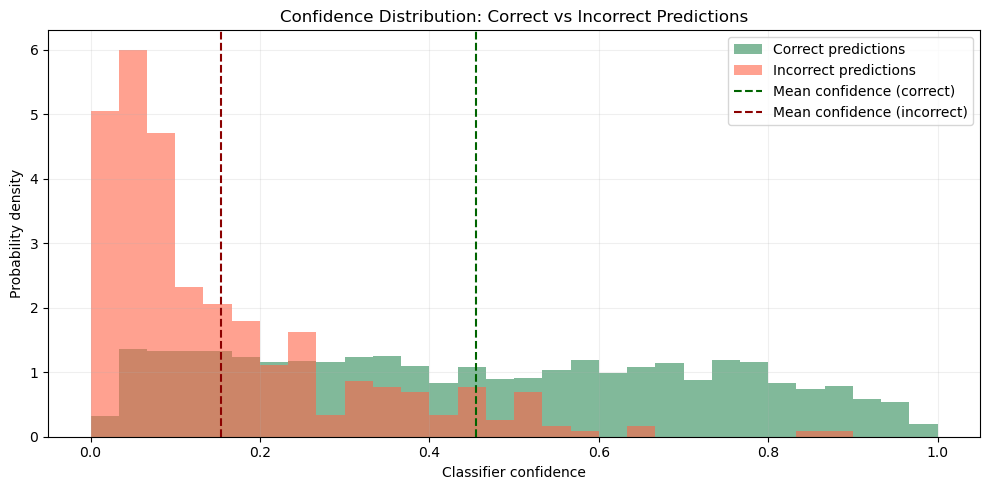

In [15]:

import matplotlib.pyplot as plt
import numpy as np

# Confidence scores for correct predictions
correct_scores = val_analysis.loc[
    val_analysis["correct"], "confidence"
]

# Confidence scores for incorrect predictions
incorrect_scores = val_analysis.loc[
    ~val_analysis["correct"], "confidence"
]

# Create the visualization
plt.figure(figsize=(10, 5))

# Common bins for both distributions
bins = np.linspace(0, 1, 31)

plt.hist(
    correct_scores,
    bins=bins,
    alpha=0.6,
    density=True,
    label="Correct predictions",
    color="seagreen"
)

plt.hist(
    incorrect_scores,
    bins=bins,
    alpha=0.6,
    density=True,
    label="Incorrect predictions",
    color="tomato"
)

# Mark average confidence levels
plt.axvline(
    correct_scores.mean(),
    color="darkgreen",
    linestyle="--",
    label="Mean confidence (correct)"
)

plt.axvline(
    incorrect_scores.mean(),
    color="darkred",
    linestyle="--",
    label="Mean confidence (incorrect)"
)

plt.xlabel("Classifier confidence")
plt.ylabel("Probability density")
plt.title("Confidence Distribution: Correct vs Incorrect Predictions")

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.show()


In [16]:

threshold = 0.50

# Number of mistakes above the chosen threshold
high_conf_errors = incorrect_scores >= threshold

print("CONFIDENCE THRESHOLD ANALYSIS")
print("-" * 40)

print("Threshold:", threshold)
print("Total incorrect predictions:", len(incorrect_scores))
print("Incorrect predictions above threshold:",
      high_conf_errors.sum())

print(
    "Percentage of mistakes above threshold:",
    f"{high_conf_errors.mean() * 100:.2f}%"
)

# Evaluate the predictions accepted by this threshold
accepted = val_analysis["confidence"] >= threshold

accepted_count = accepted.sum()

if accepted_count > 0:
    accepted_error_rate = (
        ~val_analysis.loc[accepted, "correct"]
    ).mean()

    print("Automation coverage:",
          f"{accepted.mean() * 100:.2f}%")

    print("Error rate among accepted queries:",
          f"{accepted_error_rate * 100:.2f}%")


CONFIDENCE THRESHOLD ANALYSIS
----------------------------------------
Threshold: 0.5
Total incorrect predictions: 350
Incorrect predictions above threshold: 15
Percentage of mistakes above threshold: 4.29%
Automation coverage: 39.47%
Error rate among accepted queries: 1.27%


In [17]:

import numpy as np

# Number of validation queries
n_val = X_val.shape[0]

# Store the highest similarity and nearest training index
nearest_similarity = np.zeros(n_val)
nearest_train_index = np.zeros(n_val, dtype=int)

# Process validation queries in small batches
batch_size = 100

for start in range(0, n_val, batch_size):

    end = min(start + batch_size, n_val)

    # Calculate cosine similarity with training queries
    # TF-IDF vectors are L2-normalized by default
    similarity_matrix = (
        X_val[start:end] @ X_train.T
    ).toarray()

    # Find the closest training example for each query
    best_indices = np.argmax(
        similarity_matrix,
        axis=1
    )

    best_scores = similarity_matrix[
        np.arange(end - start),
        best_indices
    ]

    nearest_similarity[start:end] = best_scores
    nearest_train_index[start:end] = best_indices

# Add the new signal to our validation analysis
val_analysis["tfidf_nn_similarity"] = nearest_similarity

# Retrieve the nearest training text and intent
val_analysis["nearest_training_text"] = (
    train_df.iloc[nearest_train_index]["text"].to_numpy()
)

val_analysis["nearest_training_intent"] = (
    train_df.iloc[nearest_train_index]["intent"].to_numpy()
)

print("TF-IDF nearest-neighbor similarity completed!")
print("-" * 50)

print(
    "Mean similarity (correct):",
    round(
        val_analysis.loc[
            val_analysis["correct"],
            "tfidf_nn_similarity"
        ].mean(), 4
    )
)

print(
    "Mean similarity (incorrect):",
    round(
        val_analysis.loc[
            ~val_analysis["correct"],
            "tfidf_nn_similarity"
        ].mean(), 4
    )
)

print("\nExample nearest-neighbor matches:")

display(
    val_analysis[
        [
            "text",
            "intent",
            "predicted_intent",
            "tfidf_nn_similarity",
            "nearest_training_text",
            "nearest_training_intent"
        ]
    ].sample(8, random_state=42)
)


TF-IDF nearest-neighbor similarity completed!
--------------------------------------------------
Mean similarity (correct): 0.5907
Mean similarity (incorrect): 0.4716

Example nearest-neighbor matches:


,text,intent,predicted_intent,tfidf_nn_similarity,nearest_training_text,nearest_training_intent
1801,"who is your supervisor, please",who_do_you_work_for,who_do_you_work_for,0.614865,am i your supervisor,who_do_you_work_for
1190,let me know what today's date is,date,date,0.741000,i would like to know what today's date is,date
1817,provide me the name of your boss,who_do_you_work_for,who_do_you_work_for,0.758859,what is the name of your boss,who_do_you_work_for
251,when did i get my check last,payday,last_maintenance,0.673079,when did i get my last paycheck,payday
2505,i want to find a round trip flight from denver...,book_flight,book_flight,0.351951,book a flight from denver to austin on the 16t...,book_flight
1117,how many grams of sodium are in potato chips,nutrition_info,measurement_conversion,0.346676,what is the total number of calories in a bag ...,calories
1411,i have a card that was lost i need to report,report_lost_card,report_lost_card,0.427794,i need to report a lost card,report_lost_card
2113,set all doors to locked,smart_home,smart_home,0.587025,make sure all doors are locked,smart_home


In [18]:

import numpy as np

def calculate_knn_agreement(
    query_vectors,
    training_vectors,
    training_labels,
    k=5,
    batch_size=100
):
    """
    Calculate similarity-weighted agreement among
    the k nearest training examples.

    Returns:
        agreement_scores: Neighbor consensus scores
        majority_intents: Winning neighbor intent
    """

    training_labels = np.asarray(training_labels)

    n_queries = query_vectors.shape[0]

    agreement_scores = np.zeros(n_queries)

    majority_intents = np.empty(
        n_queries,
        dtype=object
    )

    for start in range(0, n_queries, batch_size):

        end = min(start + batch_size, n_queries)

        # Compare query vectors with training vectors
        similarities = (
            query_vectors[start:end] @ training_vectors.T
        ).toarray()

        # Identify the five nearest training examples
        top_indices = np.argpartition(
            -similarities,
            kth=k - 1,
            axis=1
        )[:, :k]

        top_scores = np.take_along_axis(
            similarities,
            top_indices,
            axis=1
        )

        # Calculate weighted votes for each query
        for row in range(end - start):

            neighbor_indices = top_indices[row]
            neighbor_scores = top_scores[row]

            votes = {}

            for index, score in zip(
                neighbor_indices,
                neighbor_scores
            ):

                intent = training_labels[index]
                weight = max(float(score), 0.0)

                votes[intent] = (
                    votes.get(intent, 0.0) + weight
                )

            total_weight = sum(votes.values())

            if total_weight > 0:

                winning_intent = max(
                    votes,
                    key=votes.get
                )

                agreement = (
                    votes[winning_intent] / total_weight
                )

            else:
                winning_intent = None
                agreement = 0.0

            position = start + row

            majority_intents[position] = winning_intent
            agreement_scores[position] = agreement

    return agreement_scores, majority_intents


# Calculate kNN signals on validation data
knn_agreement, knn_majority = calculate_knn_agreement(
    query_vectors=X_val,
    training_vectors=X_train,
    training_labels=y_train,
    k=5
)

# Save results in our analysis DataFrame
val_analysis["knn_agreement"] = knn_agreement

val_analysis["knn_majority_intent"] = knn_majority

# Diagnostic: Do neighbors support the classifier?
val_analysis["knn_matches_classifier"] = (
    val_analysis["knn_majority_intent"]
    == val_analysis["predicted_intent"]
)

# Compare scores for correct and incorrect predictions
print("KNN AGREEMENT ANALYSIS")
print("-" * 45)

print(
    "Mean agreement (correct):",
    round(
        val_analysis.loc[
            val_analysis["correct"],
            "knn_agreement"
        ].mean(), 4
    )
)

print(
    "Mean agreement (incorrect):",
    round(
        val_analysis.loc[
            ~val_analysis["correct"],
            "knn_agreement"
        ].mean(), 4
    )
)

print(
    "Classifier-neighbor match rate:",
    f"{val_analysis['knn_matches_classifier'].mean():.2%}"
)

print("\nSample results:")

display(
    val_analysis[
        [
            "text",
            "intent",
            "predicted_intent",
            "knn_majority_intent",
            "knn_agreement",
            "knn_matches_classifier"
        ]
    ].sample(10, random_state=42)
)


KNN AGREEMENT ANALYSIS
---------------------------------------------
Mean agreement (correct): 0.8147
Mean agreement (incorrect): 0.563
Classifier-neighbor match rate: 82.53%

Sample results:


,text,intent,predicted_intent,knn_majority_intent,knn_agreement,knn_matches_classifier
1801,"who is your supervisor, please",who_do_you_work_for,who_do_you_work_for,who_do_you_work_for,0.816657,True
1190,let me know what today's date is,date,date,date,1.000000,True
1817,provide me the name of your boss,who_do_you_work_for,who_do_you_work_for,who_do_you_work_for,0.834200,True
251,when did i get my check last,payday,last_maintenance,payday,0.440418,False
2505,i want to find a round trip flight from denver...,book_flight,book_flight,book_flight,0.633374,True
1117,how many grams of sodium are in potato chips,nutrition_info,measurement_conversion,ingredients_list,0.578021,False
1411,i have a card that was lost i need to report,report_lost_card,report_lost_card,report_lost_card,1.000000,True
2113,set all doors to locked,smart_home,smart_home,smart_home,1.000000,True
408,"i have no oranges, put them onto my list",shopping_list_update,shopping_list_update,maybe,0.399891,False
2579,could you tell me the amount owed on gas and e...,bill_balance,gas,gas,0.818114,True


In [19]:

from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize

# Number of dimensions for LSA
LSA_DIMENSIONS = 300

# Create the SVD model
lsa_model = TruncatedSVD(
    n_components=LSA_DIMENSIONS,
    random_state=42
)

# Learn the reduced representation from training data
X_train_lsa = lsa_model.fit_transform(X_train)

# Apply the learned transformation to validation data
X_val_lsa = lsa_model.transform(X_val)

# Normalize vectors for cosine similarity
X_train_lsa = normalize(X_train_lsa)
X_val_lsa = normalize(X_val_lsa)

# Display results
print("LSA embedding generation completed!")
print("-" * 45)

print("Original TF-IDF shape:", X_train.shape)
print("LSA training shape:", X_train_lsa.shape)
print("LSA validation shape:", X_val_lsa.shape)

print(
    "Explained variance ratio:",
    round(
        lsa_model.explained_variance_ratio_.sum(),
        4
    )
)


LSA embedding generation completed!
---------------------------------------------
Original TF-IDF shape: (15000, 30848)
LSA training shape: (15000, 300)
LSA validation shape: (3000, 300)
Explained variance ratio: 0.333


In [20]:

import numpy as np

# Number of validation queries
n_val = X_val_lsa.shape[0]

# Arrays to store nearest-neighbor results
lsa_nearest_similarity = np.zeros(n_val)

lsa_nearest_index = np.zeros(
    n_val,
    dtype=int
)

# Process queries in batches
batch_size = 100

for start in range(0, n_val, batch_size):

    end = min(start + batch_size, n_val)

    # Calculate cosine similarities
    # LSA vectors were normalized in Cell 15
    similarities = (
        X_val_lsa[start:end] @ X_train_lsa.T
    )

    # Find the most similar training example
    best_indices = np.argmax(
        similarities,
        axis=1
    )

    best_scores = similarities[
        np.arange(end - start),
        best_indices
    ]

    # Store results
    lsa_nearest_similarity[start:end] = best_scores

    lsa_nearest_index[start:end] = best_indices


# Add LSA similarity to our analysis DataFrame
val_analysis["lsa_nn_similarity"] = (
    lsa_nearest_similarity
)

# Retrieve nearest training texts and intents
val_analysis["nearest_lsa_text"] = (
    train_df.iloc[lsa_nearest_index]["text"].to_numpy()
)

val_analysis["nearest_lsa_intent"] = (
    train_df.iloc[lsa_nearest_index]["intent"].to_numpy()
)

# Compare similarity for correct and incorrect predictions
print("LSA NEAREST-NEIGHBOR ANALYSIS")
print("-" * 50)

correct_lsa = val_analysis.loc[
    val_analysis["correct"],
    "lsa_nn_similarity"
]

incorrect_lsa = val_analysis.loc[
    ~val_analysis["correct"],
    "lsa_nn_similarity"
]

print(
    f"Mean LSA similarity (correct): "
    f"{correct_lsa.mean():.4f}"
)

print(
    f"Mean LSA similarity (incorrect): "
    f"{incorrect_lsa.mean():.4f}"
)

print("\nSample nearest-neighbor matches:")

display(
    val_analysis[
        [
            "text",
            "intent",
            "predicted_intent",
            "lsa_nn_similarity",
            "nearest_lsa_text",
            "nearest_lsa_intent"
        ]
    ].sample(8, random_state=42)
)


LSA NEAREST-NEIGHBOR ANALYSIS
--------------------------------------------------
Mean LSA similarity (correct): 0.8553
Mean LSA similarity (incorrect): 0.7908

Sample nearest-neighbor matches:


,text,intent,predicted_intent,lsa_nn_similarity,nearest_lsa_text,nearest_lsa_intent
1801,"who is your supervisor, please",who_do_you_work_for,who_do_you_work_for,0.949229,who is your manager,who_do_you_work_for
1190,let me know what today's date is,date,date,0.757585,let me know what i have to do today,todo_list
1817,provide me the name of your boss,who_do_you_work_for,who_do_you_work_for,0.821706,what is the name of your boss,who_do_you_work_for
251,when did i get my check last,payday,last_maintenance,0.833694,when did i get my last paycheck,payday
2505,i want to find a round trip flight from denver...,book_flight,book_flight,0.788918,i want to book a flight reservation from texas...,book_flight
1117,how many grams of sodium are in potato chips,nutrition_info,measurement_conversion,0.951312,how many ounces are in a cup,measurement_conversion
1411,i have a card that was lost i need to report,report_lost_card,report_lost_card,0.834141,i need to report a lost card,report_lost_card
2113,set all doors to locked,smart_home,smart_home,0.714260,set temperature to 75,smart_home


In [21]:

import numpy as np
from scipy import sparse

def knn_reliability(
    query_vectors,
    training_vectors,
    training_labels,
    k=5,
    batch_size=100
):
    """
    Calculate similarity-weighted kNN consensus.

    Supports both sparse TF-IDF vectors and
    dense LSA embeddings.

    Returns
    -------
    agreement_scores : array
        Weighted agreement among the k neighbors.

    majority_intents : array
        Intent receiving the highest weighted vote.
    """

    training_labels = np.asarray(training_labels)

    n_queries = query_vectors.shape[0]

    agreement_scores = np.zeros(n_queries)
    majority_intents = np.empty(n_queries, dtype=object)

    for start in range(0, n_queries, batch_size):

        end = min(start + batch_size, n_queries)

        # Cosine similarity for normalized vectors
        similarities = (
            query_vectors[start:end] @ training_vectors.T
        )

        # Convert sparse results only when necessary
        if sparse.issparse(similarities):
            similarities = similarities.toarray()
        else:
            similarities = np.asarray(similarities)

        # Find the k nearest training examples
        top_indices = np.argpartition(
            -similarities,
            kth=k - 1,
            axis=1
        )[:, :k]

        top_scores = np.take_along_axis(
            similarities,
            top_indices,
            axis=1
        )

        # Calculate weighted votes
        for row in range(end - start):

            votes = {}

            for idx, score in zip(
                top_indices[row],
                top_scores[row]
            ):

                intent = training_labels[idx]

                # Negative similarities contribute no weight
                weight = max(float(score), 0.0)

                votes[intent] = (
                    votes.get(intent, 0.0) + weight
                )

            total_weight = sum(votes.values())

            position = start + row

            if total_weight > 0:

                winning_intent = max(
                    votes,
                    key=votes.get
                )

                agreement = (
                    votes[winning_intent] / total_weight
                )

            else:
                winning_intent = None
                agreement = 0.0

            majority_intents[position] = winning_intent
            agreement_scores[position] = agreement

    return agreement_scores, majority_intents


# Calculate agreement using LSA embeddings
lsa_knn_agreement, lsa_knn_majority = knn_reliability(
    query_vectors=X_val_lsa,
    training_vectors=X_train_lsa,
    training_labels=y_train,
    k=5
)

# Store the results
val_analysis["lsa_knn_agreement"] = lsa_knn_agreement

val_analysis["lsa_knn_majority_intent"] = (
    lsa_knn_majority
)

# Check agreement with Logistic Regression
val_analysis["lsa_knn_matches_classifier"] = (
    val_analysis["lsa_knn_majority_intent"]
    == val_analysis["predicted_intent"]
)

# Separate correct and incorrect predictions
correct_lsa_knn = val_analysis.loc[
    val_analysis["correct"],
    "lsa_knn_agreement"
]

incorrect_lsa_knn = val_analysis.loc[
    ~val_analysis["correct"],
    "lsa_knn_agreement"
]

print("LSA KNN AGREEMENT ANALYSIS")
print("-" * 45)

print(
    f"Mean agreement (correct): "
    f"{correct_lsa_knn.mean():.4f}"
)

print(
    f"Mean agreement (incorrect): "
    f"{incorrect_lsa_knn.mean():.4f}"
)

print(
    f"Classifier-neighbor match rate: "
    f"{val_analysis['lsa_knn_matches_classifier'].mean():.2%}"
)

print("\nSample results:")

display(
    val_analysis[
        [
            "text",
            "intent",
            "predicted_intent",
            "lsa_knn_majority_intent",
            "lsa_knn_agreement",
            "lsa_knn_matches_classifier"
        ]
    ].sample(10, random_state=42)
)


LSA KNN AGREEMENT ANALYSIS
---------------------------------------------
Mean agreement (correct): 0.8189
Mean agreement (incorrect): 0.5761
Classifier-neighbor match rate: 80.77%

Sample results:


,text,intent,predicted_intent,lsa_knn_majority_intent,lsa_knn_agreement,lsa_knn_matches_classifier
1801,"who is your supervisor, please",who_do_you_work_for,who_do_you_work_for,who_do_you_work_for,0.600000,True
1190,let me know what today's date is,date,date,date,0.383300,True
1817,provide me the name of your boss,who_do_you_work_for,who_do_you_work_for,who_do_you_work_for,0.603530,True
251,when did i get my check last,payday,last_maintenance,last_maintenance,0.779146,True
2505,i want to find a round trip flight from denver...,book_flight,book_flight,book_flight,1.000000,True
1117,how many grams of sodium are in potato chips,nutrition_info,measurement_conversion,spelling,0.799930,False
1411,i have a card that was lost i need to report,report_lost_card,report_lost_card,report_lost_card,0.612671,True
2113,set all doors to locked,smart_home,smart_home,smart_home,1.000000,True
408,"i have no oranges, put them onto my list",shopping_list_update,shopping_list_update,maybe,1.000000,False
2579,could you tell me the amount owed on gas and e...,bill_balance,gas,gas,0.822661,True


In [22]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
import numpy as np
import time

# Step 1: Create the second classifier
lsa_classifier = LogisticRegression(
    C=1.0,
    max_iter=1000,
    solver="lbfgs",
    random_state=42
)

# Step 2: Train on LSA embeddings
start_time = time.time()

lsa_classifier.fit(X_train_lsa, y_train)

training_time_lsa = time.time() - start_time

# Step 3: Predict validation intents
lsa_val_predictions = lsa_classifier.predict(
    X_val_lsa
)

# Step 4: Evaluate the second classifier
lsa_val_accuracy = accuracy_score(
    y_val,
    lsa_val_predictions
)

lsa_val_macro_f1 = f1_score(
    y_val,
    lsa_val_predictions,
    average="macro"
)

# Step 5: Verify that class ordering matches Model A
assert np.array_equal(
    baseline_model.classes_,
    lsa_classifier.classes_
), "Class ordering differs between classifiers."

# Step 6: Display the results
print("LSA CLASSIFIER TRAINING COMPLETED")
print("-" * 45)

print(f"Training time: {training_time_lsa:.2f} seconds")
print("Number of classes:", len(lsa_classifier.classes_))

print("\nVALIDATION PERFORMANCE")
print("-" * 45)

print(f"TF-IDF LR accuracy : {val_accuracy:.4f}")
print(f"LSA LR accuracy    : {lsa_val_accuracy:.4f}")

print(f"\nTF-IDF LR Macro-F1 : {val_macro_f1:.4f}")
print(f"LSA LR Macro-F1    : {lsa_val_macro_f1:.4f}")

# Step 7: Measure prediction agreement
prediction_agreement = np.mean(
    val_predictions == lsa_val_predictions
)

print(
    f"\nAgreement between classifiers: "
    f"{prediction_agreement:.2%}"
)


LSA CLASSIFIER TRAINING COMPLETED
---------------------------------------------
Training time: 4.23 seconds
Number of classes: 150

VALIDATION PERFORMANCE
---------------------------------------------
TF-IDF LR accuracy : 0.8833
LSA LR accuracy    : 0.8307

TF-IDF LR Macro-F1 : 0.8826
LSA LR Macro-F1    : 0.8280

Agreement between classifiers: 90.60%


In [23]:

import numpy as np
from scipy.spatial.distance import jensenshannon
from sklearn.metrics import roc_auc_score

# Step 1: Get probabilities from both classifiers
tfidf_probabilities = baseline_model.predict_proba(X_val)

lsa_probabilities = lsa_classifier.predict_proba(X_val_lsa)

# Step 2: Confirm class ordering is identical
assert np.array_equal(
    baseline_model.classes_,
    lsa_classifier.classes_
), "Classifier class ordering does not match."

# Step 3: Calculate Jensen-Shannon distance
js_distance = jensenshannon(
    tfidf_probabilities,
    lsa_probabilities,
    axis=1
)

# Step 4: Check the output
assert np.isfinite(js_distance).all()
assert len(js_distance) == len(val_analysis)

# Step 5: Store the results
val_analysis["js_distance"] = js_distance

# Higher model agreement = lower JS distance
val_analysis["model_agreement_score"] = -js_distance

val_analysis["lsa_predicted_intent"] = lsa_val_predictions

# Step 6: Compare correct and incorrect predictions
correct_js = val_analysis.loc[
    val_analysis["correct"], "js_distance"
]

incorrect_js = val_analysis.loc[
    ~val_analysis["correct"], "js_distance"
]

print("MODEL DISAGREEMENT ANALYSIS")
print("-" * 45)

print(
    f"Mean JS distance (correct): "
    f"{correct_js.mean():.4f}"
)

print(
    f"Mean JS distance (incorrect): "
    f"{incorrect_js.mean():.4f}"
)

# Step 7: Measure how well disagreement detects errors
error_labels = (~val_analysis["correct"]).astype(int)

js_error_auc = roc_auc_score(
    error_labels,
    js_distance
)

print(f"Error-detection AUROC: {js_error_auc:.4f}")

# Step 8: Show queries with highest disagreement
print("\nTop 10 queries with highest model disagreement:")

display(
    val_analysis[
        [
            "text",
            "intent",
            "predicted_intent",
            "lsa_predicted_intent",
            "correct",
            "confidence",
            "js_distance"
        ]
    ].sort_values(
        "js_distance",
        ascending=False
    ).head(10)
)


MODEL DISAGREEMENT ANALYSIS
---------------------------------------------
Mean JS distance (correct): 0.2110
Mean JS distance (incorrect): 0.2422
Error-detection AUROC: 0.5896

Top 10 queries with highest model disagreement:


,text,intent,predicted_intent,lsa_predicted_intent,correct,confidence,js_distance
2258,rescind,cancel,definition,definition,False,0.026215,0.658434
2378,hi,greeting,greeting,greeting,True,0.120334,0.640144
932,approved,yes,pto_request_status,pto_request_status,False,0.139640,0.610655
2549,"send message to carl, you suck",text,text,text,True,0.160313,0.587622
2546,text mom saying happy birthday,text,text,text,True,0.272638,0.582733
2284,can i travel to south africa without getting a...,vaccines,vaccines,vaccines,True,0.093658,0.578599
1610,how are the fried chicken at zippys,restaurant_reviews,restaurant_reviews,restaurant_reviews,True,0.057439,0.551286
2928,order more paper towels from amazon,order,order,order_checks,True,0.094889,0.547726
2078,"is there anyway, i can report a suspicious act...",report_fraud,report_fraud,report_fraud,True,0.150462,0.546962
588,who makes you,who_made_you,who_made_you,who_made_you,True,0.213150,0.546312


In [24]:

import numpy as np
from sklearn.metrics import roc_auc_score

# Step 1: Create our seventh reliability signal
val_analysis["classifier_lsa_knn_match"] = (
    val_analysis["lsa_knn_matches_classifier"].astype(int)
)

# Step 2: Separate matching and non-matching predictions
matching = val_analysis["classifier_lsa_knn_match"] == 1
non_matching = ~matching

# Step 3: Calculate overall match rate
overall_match_rate = matching.mean()

# Step 4: Compare correctness of the two groups
error_rate_match = (
    ~val_analysis.loc[matching, "correct"]
).mean()

error_rate_mismatch = (
    ~val_analysis.loc[non_matching, "correct"]
).mean()

# Step 5: Evaluate disagreement as an error indicator
error_labels = (~val_analysis["correct"]).astype(int)

disagreement_scores = (
    1 - val_analysis["classifier_lsa_knn_match"]
)

agreement_error_auc = roc_auc_score(
    error_labels,
    disagreement_scores
)

# Step 6: Display the results
print("CLASSIFIER-LSA KNN AGREEMENT ANALYSIS")
print("-" * 50)

print(f"Overall match rate: {overall_match_rate:.2%}")

print(
    f"Error rate when predictions MATCH: "
    f"{error_rate_match:.2%}"
)

print(
    f"Error rate when predictions DISAGREE: "
    f"{error_rate_mismatch:.2%}"
)

print(
    f"Disagreement error-detection AUROC: "
    f"{agreement_error_auc:.4f}"
)

# Step 7: Show some disagreement examples
print("\nExamples where classifier and LSA kNN disagree:")

display(
    val_analysis.loc[
        non_matching,
        [
            "text",
            "intent",
            "predicted_intent",
            "lsa_knn_majority_intent",
            "lsa_knn_agreement",
            "correct"
        ]
    ].sample(
        n=min(10, non_matching.sum()),
        random_state=42
    )
)


CLASSIFIER-LSA KNN AGREEMENT ANALYSIS
--------------------------------------------------
Overall match rate: 80.77%
Error rate when predictions MATCH: 6.81%
Error rate when predictions DISAGREE: 32.06%
Disagreement error-detection AUROC: 0.6903

Examples where classifier and LSA kNN disagree:


,text,intent,predicted_intent,lsa_knn_majority_intent,lsa_knn_agreement,correct
690,please let me review all items on my mastercar...,transactions,transactions,rewards_balance,0.408030,True
2065,how do i report fraud on my chase bank card,report_fraud,report_fraud,rewards_balance,0.614196,True
2686,how many gallons of gas are in my car,gas,gas,spelling,1.000000,True
602,how long will the trip to portland be,distance,cook_time,how_busy,0.409845,False
2189,can you tell me what my federal tax burden is,taxes,taxes,income,0.606162,True
881,how's my gas mileage in citys,mpg,mpg,gas,1.000000,True
976,what plan am i paying for,insurance,insurance,change_user_name,0.394619,True
179,i have a vacation request that i need made,pto_request,pto_request,pto_request_status,1.000000,True
509,will i have enough to get a new roku with my s...,balance,balance,pin_change,0.418190,True
1060,ill pass,no,goodbye,next_song,0.809845,False


In [25]:

# Define the seven reliability features
FEATURE_COLUMNS = [
    "confidence",
    "tfidf_nn_similarity",
    "knn_agreement",
    "lsa_nn_similarity",
    "lsa_knn_agreement",
    "model_agreement_score",
    "classifier_lsa_knn_match"
]

# Create a clean feature DataFrame
val_features = val_analysis[
    [
        "text",
        "intent",
        "predicted_intent",
        "correct"
    ] + FEATURE_COLUMNS
].copy()

# Rename columns for clarity
val_features = val_features.rename(
    columns={
        "intent": "true_intent",
        "correct": "is_correct"
    }
)

# Identify examples as known intents
val_features["is_oos"] = False

# Verify the dataset
assert len(val_features) == 3000

assert len(FEATURE_COLUMNS) == 7

assert val_features[FEATURE_COLUMNS].notna().all().all()

assert np.isfinite(
    val_features[FEATURE_COLUMNS].to_numpy()
).all()

print("SEVEN-SIGNAL FEATURE DATASET")
print("-" * 45)

print("Total validation queries:", len(val_features))
print("Number of reliability features:", len(FEATURE_COLUMNS))

print("\nFeature names:")
for number, feature in enumerate(FEATURE_COLUMNS, start=1):
    print(f"{number}. {feature}")

print("\nMissing feature values:",
      val_features[FEATURE_COLUMNS].isna().sum().sum())

print("\nSample feature records:")
display(val_features.head())

print("\nFeature summary:")
display(
    val_features[FEATURE_COLUMNS].describe().T[
        ["mean", "std", "min", "max"]
    ]
)


SEVEN-SIGNAL FEATURE DATASET
---------------------------------------------
Total validation queries: 3000
Number of reliability features: 7

Feature names:
1. confidence
2. tfidf_nn_similarity
3. knn_agreement
4. lsa_nn_similarity
5. lsa_knn_agreement
6. model_agreement_score
7. classifier_lsa_knn_match

Missing feature values: 0

Sample feature records:


,text,true_intent,predicted_intent,is_correct,confidence,tfidf_nn_similarity,knn_agreement,lsa_nn_similarity,lsa_knn_agreement,model_agreement_score,classifier_lsa_knn_match,is_oos
0,"in spanish, meet me tomorrow is said how",translate,translate,True,0.071407,0.338957,0.824074,0.645028,0.813637,-0.288220,0,False
1,"in french, how do i say, see you later",translate,translate,True,0.466696,0.673795,0.629005,0.716442,0.811632,-0.174094,1,False
2,how do you say hello in japanese,translate,translate,True,0.656154,0.729384,1.000000,0.970265,1.000000,-0.278161,1,False
3,how do i ask about the weather in chinese,translate,weather,False,0.158982,0.394555,1.000000,0.788884,1.000000,-0.371307,1,False
4,"how can i say ""cancel my order"" in french",translate,translate,True,0.243595,0.336657,1.000000,0.647539,0.781839,-0.234252,1,False



Feature summary:


,mean,std,min,max
confidence,0.419446,0.274405,0.013093,0.994168
tfidf_nn_similarity,0.576801,0.165708,0.000000,1.000000
knn_agreement,0.785319,0.238692,0.000000,1.000000
lsa_nn_similarity,0.847802,0.118300,0.000000,1.000000
lsa_knn_agreement,0.790545,0.249120,0.000000,1.000000
model_agreement_score,-0.214622,0.109036,-0.658434,-0.011285
classifier_lsa_knn_match,0.807667,0.394199,0.000000,1.000000


In [26]:

from scipy.spatial.distance import jensenshannon
from sklearn.preprocessing import normalize
import numpy as np
import pandas as pd

# Step 1: Load the OOS validation examples
oos_val_df = pd.DataFrame(
    data["oos_val"],
    columns=["text", "intent"]
)

assert len(oos_val_df) == 100
assert oos_val_df["intent"].eq("oos").all()

oos_texts = oos_val_df["text"]

print("OOS validation examples:", len(oos_texts))

# Step 2: Transform text using our trained models
X_oos = tfidf.transform(oos_texts)

X_oos_lsa = normalize(
    lsa_model.transform(X_oos)
)

# Step 3: Obtain classifier predictions and probabilities
oos_probabilities = baseline_model.predict_proba(X_oos)

oos_predictions = baseline_model.predict(X_oos)

oos_lsa_probabilities = lsa_classifier.predict_proba(
    X_oos_lsa
)

assert np.array_equal(
    baseline_model.classes_,
    lsa_classifier.classes_
)

# Signal 1: Classifier confidence
oos_confidence = oos_probabilities.max(axis=1)

# Signal 2: TF-IDF nearest-neighbor similarity
tfidf_similarities = (
    X_oos @ X_train.T
).toarray()

oos_tfidf_nn = tfidf_similarities.max(axis=1)

# Signal 3: TF-IDF kNN agreement
oos_tfidf_knn, _ = knn_reliability(
    X_oos,
    X_train,
    y_train,
    k=5
)

# Signal 4: LSA nearest-neighbor similarity
lsa_similarities = (
    X_oos_lsa @ X_train_lsa.T
)

oos_lsa_nn = lsa_similarities.max(axis=1)

# Signal 5: LSA kNN agreement
oos_lsa_knn, oos_lsa_majority = knn_reliability(
    X_oos_lsa,
    X_train_lsa,
    y_train,
    k=5
)

# Signal 6: Agreement between classifier distributions
oos_js_distance = jensenshannon(
    oos_probabilities,
    oos_lsa_probabilities,
    axis=1
)

oos_model_agreement = -oos_js_distance

# Signal 7: Classifier–LSA kNN match
oos_classifier_knn_match = (
    oos_predictions == oos_lsa_majority
).astype(int)

# Step 4: Organize results into a DataFrame
oos_features = pd.DataFrame({
    "text": oos_texts.to_numpy(),
    "true_intent": "oos",
    "predicted_intent": oos_predictions,
    "is_correct": False,
    "confidence": oos_confidence,
    "tfidf_nn_similarity": oos_tfidf_nn,
    "knn_agreement": oos_tfidf_knn,
    "lsa_nn_similarity": oos_lsa_nn,
    "lsa_knn_agreement": oos_lsa_knn,
    "model_agreement_score": oos_model_agreement,
    "classifier_lsa_knn_match": oos_classifier_knn_match,
    "is_oos": True
})

# Step 5: Verify that all features are valid
assert len(oos_features) == 100

assert oos_features[FEATURE_COLUMNS].notna().all().all()

assert np.isfinite(
    oos_features[FEATURE_COLUMNS].to_numpy()
).all()

print("\nOOS FEATURE EXTRACTION COMPLETED")
print("-" * 45)

print("Total OOS queries:", len(oos_features))
print("Reliability features:", len(FEATURE_COLUMNS))
print("Missing feature values:",
      oos_features[FEATURE_COLUMNS].isna().sum().sum())

print("\nAverage confidence for OOS queries:")
print(round(oos_features["confidence"].mean(), 4))

print("\nSample OOS predictions:")
display(
    oos_features[
        [
            "text",
            "predicted_intent",
            "confidence",
            "tfidf_nn_similarity",
            "lsa_nn_similarity",
            "is_oos"
        ]
    ].head(10)
)


OOS validation examples: 100

OOS FEATURE EXTRACTION COMPLETED
---------------------------------------------
Total OOS queries: 100
Reliability features: 7
Missing feature values: 0

Average confidence for OOS queries:
0.0936

Sample OOS predictions:


,text,predicted_intent,confidence,tfidf_nn_similarity,lsa_nn_similarity,is_oos
0,set a warning for when my bank account starts ...,account_blocked,0.098863,0.398302,0.722110,True
1,a show on broadway,transactions,0.173414,0.399779,0.778876,True
2,who has the best record in the nfl,who_made_you,0.043994,0.306717,0.609923,True
3,how do i find the area of a circle,recipe,0.024040,0.415020,0.788869,True
4,how many onions do i have on hand,pto_balance,0.065894,0.434549,0.860477,True
5,what is the name of the 13th president,what_song,0.087060,0.517682,0.913062,True
6,show me recent activity in my backyard,transactions,0.144342,0.611306,0.813512,True
7,how long will it take me to pay off my card if...,distance,0.084051,0.405358,0.726390,True
8,does our bank have free notary,travel_notification,0.020684,0.304344,0.729586,True
9,what were the top stories this week,where_are_you_from,0.021784,0.431293,0.617963,True


In [27]:

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# Step 1: Combine known and OOS validation examples
full_val_df = pd.concat(
    [val_features, oos_features],
    ignore_index=True
)

# Step 2: Confirm dataset integrity
assert len(full_val_df) == 3100
assert len(FEATURE_COLUMNS) == 7
assert full_val_df["is_oos"].sum() == 100

assert np.isfinite(
    full_val_df[FEATURE_COLUMNS].to_numpy()
).all()

# Step 3: Define groups for stratification
stratify_labels = np.where(
    full_val_df["is_oos"],
    "oos",
    np.where(
        full_val_df["is_correct"],
        "known_correct",
        "known_incorrect"
    )
)

# Step 4: Split validation into two independent subsets
trust_train_df, policy_val_df = train_test_split(
    full_val_df,
    test_size=0.50,
    random_state=42,
    stratify=stratify_labels
)

# Step 5: Reset row indices
trust_train_df = trust_train_df.reset_index(drop=True)
policy_val_df = policy_val_df.reset_index(drop=True)

# Step 6: Display dataset information
print("TRUST MODEL DATA PREPARATION")
print("-" * 50)

print("Complete validation set:", len(full_val_df))
print("Trust training set:", len(trust_train_df))
print("Policy validation set:", len(policy_val_df))

print("\nTrust training composition:")
print("Known queries:", (~trust_train_df["is_oos"]).sum())
print("OOS queries:", trust_train_df["is_oos"].sum())
print("Correct predictions:", trust_train_df["is_correct"].sum())

print("\nPolicy validation composition:")
print("Known queries:", (~policy_val_df["is_oos"]).sum())
print("OOS queries:", policy_val_df["is_oos"].sum())
print("Correct predictions:", policy_val_df["is_correct"].sum())

# Step 7: Verify both subsets have valid features
for subset in [trust_train_df, policy_val_df]:
    assert subset[FEATURE_COLUMNS].notna().all().all()
    assert np.isfinite(
        subset[FEATURE_COLUMNS].to_numpy()
    ).all()

print("\nValidation split completed successfully!")


TRUST MODEL DATA PREPARATION
--------------------------------------------------
Complete validation set: 3100
Trust training set: 1550
Policy validation set: 1550

Trust training composition:
Known queries: 1500
OOS queries: 50
Correct predictions: 1325

Policy validation composition:
Known queries: 1500
OOS queries: 50
Correct predictions: 1325

Validation split completed successfully!


In [28]:

import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# --------------------------------------------------
# STEP 1: Prepare trust-model features and target
# --------------------------------------------------

X_trust = trust_train_df[FEATURE_COLUMNS]

# 1 = primary classifier is correct
# 0 = primary classifier is wrong or query is OOS
y_trust = trust_train_df["is_correct"].astype(int)

# --------------------------------------------------
# STEP 2: Define our assumed OOS prevalence
# --------------------------------------------------

TARGET_OOS_PREVALENCE = 0.18

train_is_oos = trust_train_df["is_oos"].to_numpy(
    dtype=bool
)

observed_oos_prevalence = train_is_oos.mean()

# Give each group total weight proportional
# to its assumed operating prevalence.
train_weights = np.where(
    train_is_oos,
    TARGET_OOS_PREVALENCE / observed_oos_prevalence,
    (1 - TARGET_OOS_PREVALENCE)
    / (1 - observed_oos_prevalence)
)

# Verify the effective prevalence
effective_oos_prevalence = np.average(
    train_is_oos.astype(float),
    weights=train_weights
)

assert np.isclose(
    effective_oos_prevalence,
    TARGET_OOS_PREVALENCE
)

# --------------------------------------------------
# STEP 3: Create the trust-model pipeline
# --------------------------------------------------

trust_model = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "classifier",
        LogisticRegression(
            C=1.0,
            max_iter=1000,
            solver="lbfgs",
            random_state=42
        )
    )
])

# --------------------------------------------------
# STEP 4: Train using sample weights
# --------------------------------------------------

trust_model.fit(
    X_trust,
    y_trust,
    scaler__sample_weight=train_weights,
    classifier__sample_weight=train_weights
)

# --------------------------------------------------
# STEP 5: Predict trust scores on policy validation
# --------------------------------------------------

X_policy = policy_val_df[FEATURE_COLUMNS]

policy_trust_scores = trust_model.predict_proba(
    X_policy
)[:, 1]

policy_val_df["trust_score"] = policy_trust_scores

# --------------------------------------------------
# STEP 6: Prepare policy evaluation weights
# --------------------------------------------------

policy_is_oos = policy_val_df["is_oos"].to_numpy(
    dtype=bool
)

policy_oos_prevalence = policy_is_oos.mean()

policy_weights = np.where(
    policy_is_oos,
    TARGET_OOS_PREVALENCE / policy_oos_prevalence,
    (1 - TARGET_OOS_PREVALENCE)
    / (1 - policy_oos_prevalence)
)

# --------------------------------------------------
# STEP 7: Compare error-ranking ability
# --------------------------------------------------

y_policy = policy_val_df["is_correct"].astype(int)

trust_auc = roc_auc_score(
    y_policy,
    policy_val_df["trust_score"],
    sample_weight=policy_weights
)

confidence_auc = roc_auc_score(
    y_policy,
    policy_val_df["confidence"],
    sample_weight=policy_weights
)

# --------------------------------------------------
# STEP 8: Display results
# --------------------------------------------------

print("LEARNED TRUST MODEL TRAINING COMPLETED")
print("-" * 50)

print("Training examples:", len(X_trust))
print("Reliability features:", X_trust.shape[1])

print(
    f"Observed training OOS prevalence: "
    f"{observed_oos_prevalence:.2%}"
)

print(
    f"Weighted training OOS prevalence: "
    f"{effective_oos_prevalence:.2%}"
)

print("\nPOLICY VALIDATION — WEIGHTED AUROC")
print("-" * 50)

print(
    f"Confidence-only AUROC: {confidence_auc:.4f}"
)

print(
    f"Seven-signal trust AUROC: {trust_auc:.4f}"
)

print("\nTrust-score summary:")
print(
    policy_val_df["trust_score"].describe().round(4)
)

print("\nSample trust predictions:")

display(
    policy_val_df[
        [
            "text",
            "predicted_intent",
            "is_correct",
            "is_oos",
            "confidence",
            "trust_score"
        ]
    ].head(10)
)


LEARNED TRUST MODEL TRAINING COMPLETED
--------------------------------------------------
Training examples: 1550
Reliability features: 7
Observed training OOS prevalence: 3.23%
Weighted training OOS prevalence: 18.00%

POLICY VALIDATION — WEIGHTED AUROC
--------------------------------------------------
Confidence-only AUROC: 0.8800
Seven-signal trust AUROC: 0.8837

Trust-score summary:
count    1550.0000
mean        0.7827
std         0.2578
min         0.0723
25%         0.6374
50%         0.9075
75%         0.9838
max         0.9985
Name: trust_score, dtype: float64

Sample trust predictions:


,text,predicted_intent,is_correct,is_oos,confidence,trust_score
0,does boston restaurant have favorable reviews,restaurant_reviews,True,False,0.351721,0.861456
1,help me find the chase routing number,routing,True,False,0.673143,0.979953
2,please set an alarm for me,alarm,True,False,0.959942,0.997550
3,i need to report a stolen card,report_lost_card,True,False,0.705388,0.989952
4,i need you to text mickey saying 'can we resch...,text,True,False,0.181268,0.573392
5,list a few pizza places that have seating near...,current_location,False,False,0.100201,0.526575
6,i want to change my bank of america account pi...,pin_change,True,False,0.750303,0.990714
7,set my alarm for quarter after six tomorrow,alarm,True,False,0.534523,0.976135
8,do you know london's timezone,timezone,True,False,0.313346,0.599678
9,please put a block on my us bank account immed...,freeze_account,True,False,0.742612,0.991421


WEIGHTED RISK-COVERAGE COMPARISON
-------------------------------------------------------
Assumed OOS prevalence: 18%


,Target coverage,Confidence coverage,Confidence risk,Trust coverage,Trust risk
0,20%,19.99%,2.35%,19.99%,2.07%
1,40%,39.97%,4.26%,39.99%,2.40%
2,60%,59.06%,6.70%,60.00%,6.97%
3,80%,79.97%,15.03%,79.95%,15.63%


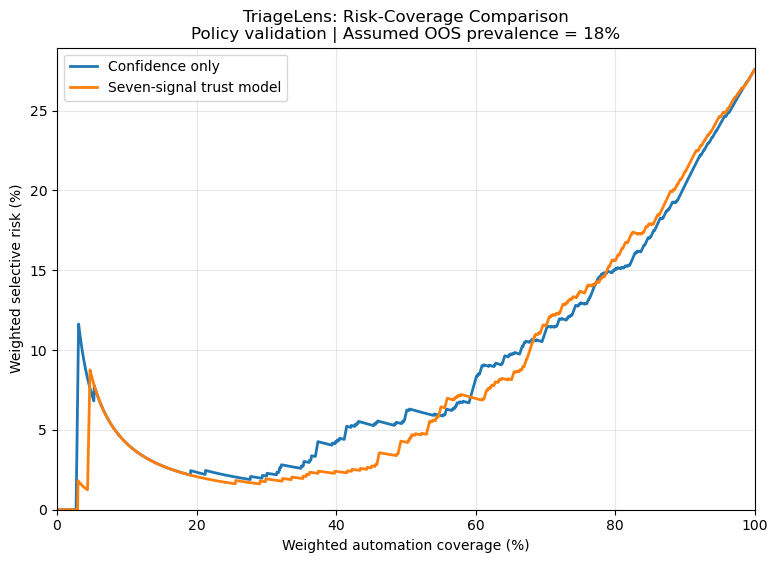

In [29]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# STEP 1: Define a weighted risk-coverage function
# --------------------------------------------------

def calculate_risk_coverage(df, score_column, weights):
    """
    Calculate weighted automation coverage and
    selective risk for every distinct score threshold.

    Higher scores indicate greater reliability.
    """

    scores = df[score_column].to_numpy(dtype=float)

    errors = (
        ~df["is_correct"].to_numpy(dtype=bool)
    ).astype(int)

    weights = np.asarray(weights, dtype=float)

    # Sort from highest reliability to lowest
    order = np.argsort(-scores, kind="stable")

    sorted_scores = scores[order]
    sorted_errors = errors[order]
    sorted_weights = weights[order]

    # Cumulative weighted accepted queries
    cumulative_weight = np.cumsum(sorted_weights)

    # Cumulative weighted incorrect predictions
    cumulative_errors = np.cumsum(
        sorted_weights * sorted_errors
    )

    # Include all queries with tied scores
    end_of_score_group = np.r_[
        sorted_scores[:-1] != sorted_scores[1:],
        True
    ]

    coverage = (
        cumulative_weight[end_of_score_group]
        / weights.sum()
    )

    selective_risk = (
        cumulative_errors[end_of_score_group]
        / cumulative_weight[end_of_score_group]
    )

    return pd.DataFrame({
        "threshold": sorted_scores[end_of_score_group],
        "coverage": coverage,
        "selective_risk": selective_risk
    })


# --------------------------------------------------
# STEP 2: Calculate both curves
# --------------------------------------------------

confidence_curve = calculate_risk_coverage(
    policy_val_df,
    "confidence",
    policy_weights
)

trust_curve = calculate_risk_coverage(
    policy_val_df,
    "trust_score",
    policy_weights
)


# --------------------------------------------------
# STEP 3: Compare at approximately equal coverage
# --------------------------------------------------

def point_at_coverage(curve, target_coverage):
    """
    Choose the largest achievable coverage
    not exceeding the target.
    """

    index = np.searchsorted(
        curve["coverage"].to_numpy(),
        target_coverage,
        side="right"
    ) - 1

    if index < 0:
        return np.nan, np.nan

    row = curve.iloc[index]

    return row["coverage"], row["selective_risk"]


target_coverages = [0.20, 0.40, 0.60, 0.80]

comparison_rows = []

for target in target_coverages:

    conf_cov, conf_risk = point_at_coverage(
        confidence_curve,
        target
    )

    trust_cov, trust_risk = point_at_coverage(
        trust_curve,
        target
    )

    comparison_rows.append({
        "Target coverage": f"{target:.0%}",
        "Confidence coverage": f"{conf_cov:.2%}",
        "Confidence risk": f"{conf_risk:.2%}",
        "Trust coverage": f"{trust_cov:.2%}",
        "Trust risk": f"{trust_risk:.2%}"
    })

comparison_df = pd.DataFrame(comparison_rows)

print("WEIGHTED RISK-COVERAGE COMPARISON")
print("-" * 55)
print("Assumed OOS prevalence: 18%")

display(comparison_df)


# --------------------------------------------------
# STEP 4: Plot risk-coverage curves
# --------------------------------------------------

plt.figure(figsize=(9, 6))

plt.plot(
    confidence_curve["coverage"] * 100,
    confidence_curve["selective_risk"] * 100,
    label="Confidence only",
    linewidth=2
)

plt.plot(
    trust_curve["coverage"] * 100,
    trust_curve["selective_risk"] * 100,
    label="Seven-signal trust model",
    linewidth=2
)

plt.xlabel("Weighted automation coverage (%)")
plt.ylabel("Weighted selective risk (%)")

plt.title(
    "TriageLens: Risk-Coverage Comparison\n"
    "Policy validation | Assumed OOS prevalence = 18%"
)

plt.legend()
plt.grid(alpha=0.3)
plt.xlim(0, 100)
plt.ylim(bottom=0)

plt.show()


COST-SENSITIVE TRIAGE ANALYSIS
--------------------------------------------------
Wrong automation cost: 10.0
Human review cost: 1.0
Assumed OOS prevalence: 18%

BEST POLICY FOR EACH METHOD


,Method,Threshold,Coverage,Selective risk,Expected cost
0,Confidence only,0.4623,34.96%,2.59%,0.7410
1,Seven-signal trust,0.8855,45.57%,2.71%,0.6678
2,Review everything,inf,0.00%,—,1.0000



Trust cost change vs confidence: +9.89% savings


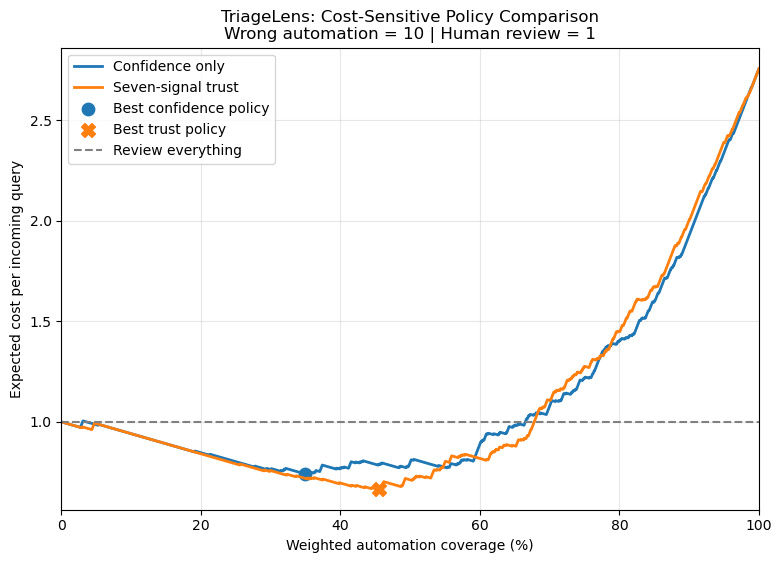

In [30]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -------------------------------------------
# Step 1: Define illustrative decision costs
# -------------------------------------------

COST_CORRECT_AUTO = 0.0
COST_WRONG_AUTO = 10.0
COST_HUMAN_REVIEW = 1.0

# -------------------------------------------
# Step 2: Calculate expected cost
# -------------------------------------------

def calculate_cost_curve(risk_coverage_curve):

    result = risk_coverage_curve.copy()

    coverage = result["coverage"]
    risk = result["selective_risk"]

    # Expected cost per incoming query
    result["expected_cost"] = (
        coverage * (
            risk * COST_WRONG_AUTO
            + (1 - risk) * COST_CORRECT_AUTO
        )
        + (1 - coverage) * COST_HUMAN_REVIEW
    )

    # Always escalating is a valid policy
    review_all = pd.DataFrame([{
        "threshold": np.inf,
        "coverage": 0.0,
        "selective_risk": np.nan,
        "expected_cost": COST_HUMAN_REVIEW
    }])

    return pd.concat(
        [review_all, result],
        ignore_index=True
    )


confidence_cost_curve = calculate_cost_curve(
    confidence_curve
)

trust_cost_curve = calculate_cost_curve(
    trust_curve
)

# -------------------------------------------
# Step 3: Select the lowest-cost threshold
# -------------------------------------------

confidence_best = confidence_cost_curve.loc[
    confidence_cost_curve["expected_cost"].idxmin()
]

trust_best = trust_cost_curve.loc[
    trust_cost_curve["expected_cost"].idxmin()
]

# -------------------------------------------
# Step 4: Build a comparison table
# -------------------------------------------

cost_comparison = pd.DataFrame([
    {
        "Method": "Confidence only",
        "Threshold": confidence_best["threshold"],
        "Coverage": confidence_best["coverage"],
        "Selective risk": confidence_best["selective_risk"],
        "Expected cost": confidence_best["expected_cost"]
    },
    {
        "Method": "Seven-signal trust",
        "Threshold": trust_best["threshold"],
        "Coverage": trust_best["coverage"],
        "Selective risk": trust_best["selective_risk"],
        "Expected cost": trust_best["expected_cost"]
    },
    {
        "Method": "Review everything",
        "Threshold": np.inf,
        "Coverage": 0.0,
        "Selective risk": np.nan,
        "Expected cost": COST_HUMAN_REVIEW
    }
])

print("COST-SENSITIVE TRIAGE ANALYSIS")
print("-" * 50)

print("Wrong automation cost:", COST_WRONG_AUTO)
print("Human review cost:", COST_HUMAN_REVIEW)
print("Assumed OOS prevalence: 18%")

print("\nBEST POLICY FOR EACH METHOD")

display(
    cost_comparison.style.format({
        "Threshold": "{:.4f}",
        "Coverage": "{:.2%}",
        "Selective risk": "{:.2%}",
        "Expected cost": "{:.4f}"
    }, na_rep="—")
)

# -------------------------------------------
# Step 5: Calculate relative cost improvement
# -------------------------------------------

baseline_cost = confidence_best["expected_cost"]
trust_cost = trust_best["expected_cost"]

relative_savings = (
    (baseline_cost - trust_cost)
    / baseline_cost
) * 100

print(
    f"\nTrust cost change vs confidence: "
    f"{relative_savings:+.2f}% savings"
)

# -------------------------------------------
# Step 6: Plot expected cost against coverage
# -------------------------------------------

plt.figure(figsize=(9, 6))

plt.plot(
    confidence_cost_curve["coverage"] * 100,
    confidence_cost_curve["expected_cost"],
    label="Confidence only",
    linewidth=2
)

plt.plot(
    trust_cost_curve["coverage"] * 100,
    trust_cost_curve["expected_cost"],
    label="Seven-signal trust",
    linewidth=2
)

plt.scatter(
    confidence_best["coverage"] * 100,
    confidence_best["expected_cost"],
    marker="o",
    s=80,
    label="Best confidence policy"
)

plt.scatter(
    trust_best["coverage"] * 100,
    trust_best["expected_cost"],
    marker="X",
    s=100,
    label="Best trust policy"
)

plt.axhline(
    COST_HUMAN_REVIEW,
    linestyle="--",
    color="gray",
    label="Review everything"
)

plt.xlabel("Weighted automation coverage (%)")
plt.ylabel("Expected cost per incoming query")

plt.title(
    "TriageLens: Cost-Sensitive Policy Comparison\n"
    "Wrong automation = 10 | Human review = 1"
)

plt.legend()
plt.grid(alpha=0.3)
plt.xlim(0, 100)

plt.show()


In [31]:

import numpy as np
import pandas as pd

# --------------------------------------------------
# STEP 1: Freeze our primary policy configuration
# --------------------------------------------------

PRIMARY_COST_RATIO = 10
TARGET_OOS_PREVALENCE = 0.18

# Save the thresholds selected in Cell 26
frozen_confidence_threshold = float(
    confidence_best["threshold"]
)

frozen_trust_threshold = float(
    trust_best["threshold"]
)

print("FROZEN PRIMARY POLICY")
print("-" * 50)

print(
    f"Confidence threshold: "
    f"{frozen_confidence_threshold:.4f}"
)

print(
    f"Trust threshold: "
    f"{frozen_trust_threshold:.4f}"
)

print("Primary cost ratio: 10:1")
print("Assumed OOS prevalence: 18%")


# --------------------------------------------------
# STEP 2: Define a cost optimization function
# --------------------------------------------------

def find_best_cost_policy(
    curve,
    wrong_cost,
    review_cost=1.0
):
    result = curve.copy()

    # Weighted expected cost at each threshold
    result["cost"] = (
        result["coverage"]
        * result["selective_risk"]
        * wrong_cost
        + (1 - result["coverage"])
        * review_cost
    )

    # Include the review-everything alternative
    review_all = pd.DataFrame([{
        "threshold": np.inf,
        "coverage": 0.0,
        "selective_risk": np.nan,
        "cost": review_cost
    }])

    result = pd.concat(
        [review_all, result],
        ignore_index=True
    )

    # Select minimum-cost validation policy
    best = result.loc[result["cost"].idxmin()]

    return best


# --------------------------------------------------
# STEP 3: Evaluate predefined cost ratios
# --------------------------------------------------

cost_ratios = [5, 10, 20]

sensitivity_results = []

for ratio in cost_ratios:

    conf_best = find_best_cost_policy(
        confidence_curve,
        wrong_cost=ratio
    )

    trust_best_ratio = find_best_cost_policy(
        trust_curve,
        wrong_cost=ratio
    )

    savings = (
        (conf_best["cost"] - trust_best_ratio["cost"])
        / conf_best["cost"]
    ) * 100

    sensitivity_results.append({
        "Cost ratio": f"{ratio}:1",
        "Confidence coverage": conf_best["coverage"],
        "Trust coverage": trust_best_ratio["coverage"],
        "Confidence cost": conf_best["cost"],
        "Trust cost": trust_best_ratio["cost"],
        "Trust savings (%)": savings
    })


# --------------------------------------------------
# STEP 4: Display results
# --------------------------------------------------

sensitivity_df = pd.DataFrame(
    sensitivity_results
)

print("\nCOST SENSITIVITY ANALYSIS")
print("-" * 50)

display(
    sensitivity_df.style.format({
        "Confidence coverage": "{:.2%}",
        "Trust coverage": "{:.2%}",
        "Confidence cost": "{:.4f}",
        "Trust cost": "{:.4f}",
        "Trust savings (%)": "{:+.2f}%"
    })
)

print(
    "\nNote: These are validation-optimized results, "
    "not final test performance."
)


FROZEN PRIMARY POLICY
--------------------------------------------------
Confidence threshold: 0.4623
Trust threshold: 0.8855
Primary cost ratio: 10:1
Assumed OOS prevalence: 18%

COST SENSITIVITY ANALYSIS
--------------------------------------------------


,Cost ratio,Confidence coverage,Trust coverage,Confidence cost,Trust cost,Trust savings (%)
0,5:1,59.06%,52.96%,0.6071,0.5955,+1.92%
1,10:1,34.96%,45.57%,0.7410,0.6678,+9.89%
2,20:1,29.39%,41.58%,0.8219,0.7765,+5.52%



Note: These are validation-optimized results, not final test performance.


In [32]:

import numpy as np
import pandas as pd

# --------------------------------------------------
# STEP 1: Load test data from the local JSON
# --------------------------------------------------

test_known_df = pd.DataFrame(
    data["test"],
    columns=["text", "intent"]
)

test_oos_df = pd.DataFrame(
    data["oos_test"],
    columns=["text", "intent"]
)

# --------------------------------------------------
# STEP 2: Verify test-set integrity
# --------------------------------------------------

assert len(test_known_df) == 4500
assert len(test_oos_df) == 1000

# Known-intent labels must be recognized by our model
known_intents = set(baseline_model.classes_)

assert set(
    test_known_df["intent"]
).issubset(known_intents)

# All OOS records should be labeled "oos"
assert test_oos_df["intent"].eq("oos").all()

# Confirm that both splits contain valid text
assert test_known_df["text"].notna().all()
assert test_oos_df["text"].notna().all()

# --------------------------------------------------
# STEP 3: Combine the two test splits
# --------------------------------------------------

test_known_df["is_oos"] = False
test_oos_df["is_oos"] = True

test_full_df = pd.concat(
    [test_known_df, test_oos_df],
    ignore_index=True
)

test_full_df = test_full_df.rename(
    columns={"intent": "true_intent"}
)

# --------------------------------------------------
# STEP 4: Verify the frozen policy settings
# --------------------------------------------------

assert np.isfinite(frozen_confidence_threshold)
assert np.isfinite(frozen_trust_threshold)

assert 0 <= frozen_confidence_threshold <= 1
assert 0 <= frozen_trust_threshold <= 1

# --------------------------------------------------
# STEP 5: Display dataset composition
# --------------------------------------------------

print("FINAL TEST DATASET PREPARATION")
print("-" * 50)

print("Known-intent test queries:", len(test_known_df))
print("OOS test queries:", len(test_oos_df))
print("Total test queries:", len(test_full_df))

print(
    "Unique known intents:",
    test_known_df["intent"].nunique()
)

print(
    "Observed test OOS prevalence:",
    f"{test_full_df['is_oos'].mean():.2%}"
)

print("\nFROZEN PRIMARY POLICY")
print("-" * 50)

print(
    "Confidence threshold:",
    round(frozen_confidence_threshold, 4)
)

print(
    "Trust threshold:",
    round(frozen_trust_threshold, 4)
)

print("Wrong automation cost: 10")
print("Human review cost: 1")
print("Target OOS prevalence: 18%")

print("\nTest dataset prepared successfully!")


FINAL TEST DATASET PREPARATION
--------------------------------------------------
Known-intent test queries: 4500
OOS test queries: 1000
Total test queries: 5500
Unique known intents: 150
Observed test OOS prevalence: 18.18%

FROZEN PRIMARY POLICY
--------------------------------------------------
Confidence threshold: 0.4623
Trust threshold: 0.8855
Wrong automation cost: 10
Human review cost: 1
Target OOS prevalence: 18%

Test dataset prepared successfully!


In [33]:

import numpy as np
import pandas as pd

from scipy import sparse
from scipy.spatial.distance import jensenshannon
from sklearn.preprocessing import normalize


# --------------------------------------------------
# STEP 1: Reusable nearest-neighbor feature function
# --------------------------------------------------

def extract_neighbor_features(
    query_vectors,
    training_vectors,
    training_labels,
    k=5,
    batch_size=100
):
    """
    Calculate:
      1. Nearest-neighbor cosine similarity
      2. Similarity-weighted kNN consensus
      3. Winning kNN intent

    Supports sparse TF-IDF and dense LSA vectors.
    Both inputs must already be L2-normalized.
    """

    training_labels = np.asarray(training_labels)

    n_queries = query_vectors.shape[0]

    nearest_scores = np.zeros(n_queries)
    agreement_scores = np.zeros(n_queries)

    majority_intents = np.empty(
        n_queries,
        dtype=object
    )

    for start in range(0, n_queries, batch_size):

        end = min(start + batch_size, n_queries)

        # Calculate cosine similarities
        similarities = (
            query_vectors[start:end] @ training_vectors.T
        )

        if sparse.issparse(similarities):
            similarities = similarities.toarray()
        else:
            similarities = np.asarray(similarities)

        # Signal: nearest-neighbor similarity
        nearest_scores[start:end] = (
            similarities.max(axis=1)
        )

        # Find the k closest training examples
        top_indices = np.argpartition(
            -similarities,
            kth=k - 1,
            axis=1
        )[:, :k]

        top_scores = np.take_along_axis(
            similarities,
            top_indices,
            axis=1
        )

        # Weighted intent voting
        for row in range(end - start):

            votes = {}

            for idx, score in zip(
                top_indices[row],
                top_scores[row]
            ):
                intent = training_labels[idx]
                weight = max(float(score), 0.0)

                votes[intent] = (
                    votes.get(intent, 0.0) + weight
                )

            total_weight = sum(votes.values())

            if total_weight > 0:
                winner = max(votes, key=votes.get)
                agreement = (
                    votes[winner] / total_weight
                )
            else:
                winner = None
                agreement = 0.0

            position = start + row

            majority_intents[position] = winner
            agreement_scores[position] = agreement

    return (
        nearest_scores,
        agreement_scores,
        majority_intents
    )


# --------------------------------------------------
# STEP 2: Transform test queries
# --------------------------------------------------

test_texts = test_full_df["text"]

X_test = tfidf.transform(test_texts)

X_test_lsa = normalize(
    lsa_model.transform(X_test)
)

print("Test TF-IDF shape:", X_test.shape)
print("Test LSA shape:", X_test_lsa.shape)


# --------------------------------------------------
# STEP 3: Primary classifier
# --------------------------------------------------

test_predictions = baseline_model.predict(X_test)

test_probabilities = baseline_model.predict_proba(
    X_test
)

# Signal 1: Classifier confidence
test_confidence = test_probabilities.max(axis=1)


# --------------------------------------------------
# STEP 4: TF-IDF neighbor signals
# --------------------------------------------------

(
    test_tfidf_nn,
    test_tfidf_knn,
    test_tfidf_majority
) = extract_neighbor_features(
    X_test,
    X_train,
    y_train,
    k=5
)


# --------------------------------------------------
# STEP 5: LSA neighbor signals
# --------------------------------------------------

(
    test_lsa_nn,
    test_lsa_knn,
    test_lsa_majority
) = extract_neighbor_features(
    X_test_lsa,
    X_train_lsa,
    y_train,
    k=5
)


# --------------------------------------------------
# STEP 6: Model disagreement
# --------------------------------------------------

assert np.array_equal(
    baseline_model.classes_,
    lsa_classifier.classes_
)

test_lsa_probabilities = (
    lsa_classifier.predict_proba(X_test_lsa)
)

test_js_distance = jensenshannon(
    test_probabilities,
    test_lsa_probabilities,
    axis=1
)

# Signal 6: Negative Jensen-Shannon distance
test_model_agreement = -test_js_distance


# --------------------------------------------------
# STEP 7: Classifier-LSA kNN match
# --------------------------------------------------

test_classifier_knn_match = (
    test_predictions == test_lsa_majority
).astype(int)


# --------------------------------------------------
# STEP 8: Build the test feature DataFrame
# --------------------------------------------------

test_features = test_full_df.copy()

test_features["predicted_intent"] = test_predictions

# OOS queries cannot be correctly classified
# by the 150-class primary classifier.
test_features["is_correct"] = (
    (~test_features["is_oos"])
    & (
        test_features["true_intent"]
        == test_features["predicted_intent"]
    )
)

test_features["confidence"] = test_confidence

test_features["tfidf_nn_similarity"] = test_tfidf_nn

test_features["knn_agreement"] = test_tfidf_knn

test_features["lsa_nn_similarity"] = test_lsa_nn

test_features["lsa_knn_agreement"] = test_lsa_knn

test_features["model_agreement_score"] = (
    test_model_agreement
)

test_features["classifier_lsa_knn_match"] = (
    test_classifier_knn_match
)


# --------------------------------------------------
# STEP 9: Predict using the FROZEN trust model
# --------------------------------------------------

test_features["trust_score"] = (
    trust_model.predict_proba(
        test_features[FEATURE_COLUMNS]
    )[:, 1]
)


# --------------------------------------------------
# STEP 10: Check the final feature dataset
# --------------------------------------------------

assert len(test_features) == 5500

assert len(FEATURE_COLUMNS) == 7

assert test_features[FEATURE_COLUMNS].notna().all().all()

assert np.isfinite(
    test_features[
        FEATURE_COLUMNS + ["trust_score"]
    ].to_numpy()
).all()

assert test_features["trust_score"].between(0, 1).all()

print("\nFINAL TEST FEATURE EXTRACTION COMPLETED")
print("-" * 50)

print("Test examples:", len(test_features))
print("Reliability features:", len(FEATURE_COLUMNS))
print("Trust scores generated:", test_features["trust_score"].count())

print(
    "Missing feature values:",
    test_features[FEATURE_COLUMNS].isna().sum().sum()
)

print("\nSample predictions and reliability scores:")

display(
    test_features[
        [
            "text",
            "predicted_intent",
            "confidence",
            "tfidf_nn_similarity",
            "lsa_nn_similarity",
            "trust_score"
        ]
    ].head(8)
)


Test TF-IDF shape: (5500, 30848)
Test LSA shape: (5500, 300)

FINAL TEST FEATURE EXTRACTION COMPLETED
--------------------------------------------------
Test examples: 5500
Reliability features: 7
Trust scores generated: 5500
Missing feature values: 0

Sample predictions and reliability scores:


,text,predicted_intent,confidence,tfidf_nn_similarity,lsa_nn_similarity,trust_score
0,how would you say fly in italian,translate,0.373788,0.368763,0.898734,0.675866
1,what's the spanish word for pasta,translate,0.033685,0.417586,0.911503,0.208386
2,how would they say butter in zambia,translate,0.480840,0.606528,0.951037,0.969660
3,how do you say fast in spanish,translate,0.785229,0.671090,0.992086,0.987933
4,what's the word for trees in norway,definition,0.083735,0.517789,0.856186,0.354280
5,how does one say wonderful in german,translate,0.120902,0.601657,0.667183,0.754697
6,how do they say tacos in mexico,translate,0.450416,0.487335,0.985066,0.933279
7,how would one say cruiser in china,translate,0.228374,0.374166,0.748007,0.794346


In [34]:

import numpy as np
import pandas as pd

# --------------------------------------------------
# STEP 1: Define frozen evaluation assumptions
# --------------------------------------------------

TEST_OOS_PREVALENCE = 0.18

WRONG_AUTO_COST = 10.0
HUMAN_REVIEW_COST = 1.0
CORRECT_AUTO_COST = 0.0

# Verify our frozen policy settings
assert np.isfinite(frozen_confidence_threshold)
assert np.isfinite(frozen_trust_threshold)

assert len(test_features) == 5500

# --------------------------------------------------
# STEP 2: Prepare test labels
# --------------------------------------------------

test_is_oos = test_features["is_oos"].to_numpy(
    dtype=bool
)

test_is_correct = test_features["is_correct"].to_numpy(
    dtype=bool
)

# OOS examples must count as incorrect
# if the primary classifier handles them automatically.
assert not test_is_correct[test_is_oos].any()

# --------------------------------------------------
# STEP 3: Calculate evaluation weights
# --------------------------------------------------

observed_test_oos = test_is_oos.mean()

test_weights = np.where(
    test_is_oos,
    TEST_OOS_PREVALENCE / observed_test_oos,
    (1 - TEST_OOS_PREVALENCE)
    / (1 - observed_test_oos)
)

effective_test_oos = np.average(
    test_is_oos.astype(float),
    weights=test_weights
)

assert np.isclose(
    effective_test_oos,
    TEST_OOS_PREVALENCE
)

# --------------------------------------------------
# STEP 4: Define frozen policy evaluation function
# --------------------------------------------------

def evaluate_frozen_policy(
    scores,
    threshold,
    is_correct,
    is_oos,
    weights,
    method_name
):
    # Queries accepted for automation
    accepted = np.asarray(scores) >= threshold

    # Queries sent for human review
    escalated = ~accepted

    # Incorrect automated predictions
    wrong_automated = accepted & (~is_correct)

    total_weight = weights.sum()
    accepted_weight = weights[accepted].sum()

    # Weighted automation coverage
    coverage = accepted_weight / total_weight

    # Weighted selective risk
    if accepted_weight > 0:
        selective_risk = (
            weights[wrong_automated].sum()
            / accepted_weight
        )
    else:
        selective_risk = np.nan

    # Fraction of OOS queries automated
    oos_leakage = (
        weights[accepted & is_oos].sum()
        / weights[is_oos].sum()
    )

    # Decision cost for each incoming query
    query_costs = np.where(
        escalated,
        HUMAN_REVIEW_COST,
        np.where(
            is_correct,
            CORRECT_AUTO_COST,
            WRONG_AUTO_COST
        )
    )

    expected_cost = np.average(
        query_costs,
        weights=weights
    )

    return {
        "Method": method_name,
        "Threshold": threshold,
        "Coverage": coverage,
        "Selective risk": selective_risk,
        "OOS leakage": oos_leakage,
        "Expected cost": expected_cost,
        "Automated (count)": int(accepted.sum()),
        "Wrong automated (count)": int(
            wrong_automated.sum()
        )
    }


# --------------------------------------------------
# STEP 5: Evaluate confidence-only policy
# --------------------------------------------------

confidence_test_result = evaluate_frozen_policy(
    scores=test_features["confidence"].to_numpy(),
    threshold=frozen_confidence_threshold,
    is_correct=test_is_correct,
    is_oos=test_is_oos,
    weights=test_weights,
    method_name="Confidence only"
)

# --------------------------------------------------
# STEP 6: Evaluate seven-signal trust policy
# --------------------------------------------------

trust_test_result = evaluate_frozen_policy(
    scores=test_features["trust_score"].to_numpy(),
    threshold=frozen_trust_threshold,
    is_correct=test_is_correct,
    is_oos=test_is_oos,
    weights=test_weights,
    method_name="Seven-signal trust"
)

# --------------------------------------------------
# STEP 7: Build the final comparison table
# --------------------------------------------------

final_test_results = pd.DataFrame([
    confidence_test_result,
    trust_test_result
])

print("FINAL FROZEN TEST EVALUATION")
print("=" * 55)

print("Test examples:", len(test_features))

print(
    f"Observed OOS prevalence: "
    f"{observed_test_oos:.2%}"
)

print(
    f"Weighted OOS prevalence: "
    f"{effective_test_oos:.2%}"
)

print(
    f"Wrong automation cost: {WRONG_AUTO_COST:.0f}"
)

print(
    f"Human review cost: {HUMAN_REVIEW_COST:.0f}"
)

print("\nFINAL POLICY COMPARISON")
print("-" * 55)

display(
    final_test_results.style.format({
        "Threshold": "{:.4f}",
        "Coverage": "{:.2%}",
        "Selective risk": "{:.2%}",
        "OOS leakage": "{:.2%}",
        "Expected cost": "{:.4f}"
    })
)

# --------------------------------------------------
# STEP 8: Calculate final cost savings
# --------------------------------------------------

confidence_final_cost = (
    confidence_test_result["Expected cost"]
)

trust_final_cost = (
    trust_test_result["Expected cost"]
)

absolute_cost_reduction = (
    confidence_final_cost - trust_final_cost
)

relative_cost_savings = (
    absolute_cost_reduction
    / confidence_final_cost
) * 100

print("\nFINAL COST COMPARISON")
print("-" * 55)

print(
    f"Confidence-only expected cost: "
    f"{confidence_final_cost:.4f}"
)

print(
    f"Seven-signal expected cost: "
    f"{trust_final_cost:.4f}"
)

print(
    f"Absolute cost reduction: "
    f"{absolute_cost_reduction:+.4f}"
)

print(
    f"Relative trust-model savings: "
    f"{relative_cost_savings:+.2f}%"
)

print(
    "\nPositive savings favor the trust model; "
    "negative savings favor confidence-only triage."
)


FINAL FROZEN TEST EVALUATION
Test examples: 5500
Observed OOS prevalence: 18.18%
Weighted OOS prevalence: 18.00%
Wrong automation cost: 10
Human review cost: 1

FINAL POLICY COMPARISON
-------------------------------------------------------


,Method,Threshold,Coverage,Selective risk,OOS leakage,Expected cost,Automated (count),Wrong automated (count)
0,Confidence only,0.4623,35.58%,2.35%,1.60%,0.7276,1953,46
1,Seven-signal trust,0.8855,48.30%,3.04%,2.90%,0.6639,2651,81



FINAL COST COMPARISON
-------------------------------------------------------
Confidence-only expected cost: 0.7276
Seven-signal expected cost: 0.6639
Absolute cost reduction: +0.0637
Relative trust-model savings: +8.75%

Positive savings favor the trust model; negative savings favor confidence-only triage.


In [35]:

import numpy as np
import pandas as pd

# --------------------------------------------------
# STEP 1: Frozen settings
# --------------------------------------------------

N_BOOTSTRAP = 3000
RANDOM_SEED = 42

OOS_PREVALENCE = 0.18
WRONG_COST = 10.0
REVIEW_COST = 1.0

rng = np.random.default_rng(RANDOM_SEED)

# --------------------------------------------------
# STEP 2: Prepare paired outcomes
# --------------------------------------------------

is_oos = test_features["is_oos"].to_numpy(dtype=bool)
is_correct = test_features["is_correct"].to_numpy(dtype=bool)

confidence_accept = (
    test_features["confidence"].to_numpy()
    >= frozen_confidence_threshold
)

trust_accept = (
    test_features["trust_score"].to_numpy()
    >= frozen_trust_threshold
)

known_indices = np.flatnonzero(~is_oos)
oos_indices = np.flatnonzero(is_oos)

# Cost for every test query under each policy
confidence_costs = np.where(
    confidence_accept,
    np.where(is_correct, 0.0, WRONG_COST),
    REVIEW_COST
)

trust_costs = np.where(
    trust_accept,
    np.where(is_correct, 0.0, WRONG_COST),
    REVIEW_COST
)

# Indicators for coverage and automated errors
confidence_accepted = confidence_accept.astype(float)
trust_accepted = trust_accept.astype(float)

confidence_errors = (
    confidence_accept & ~is_correct
).astype(float)

trust_errors = (
    trust_accept & ~is_correct
).astype(float)


# --------------------------------------------------
# STEP 3: Calculate statistics for one paired sample
# --------------------------------------------------

def bootstrap_statistics(known_rows, oos_rows):

    # Weighted average under 18% OOS prevalence
    def mixture_mean(values):
        return (
            (1 - OOS_PREVALENCE)
            * values[known_rows].mean()
            + OOS_PREVALENCE
            * values[oos_rows].mean()
        )

    # Expected decision costs
    conf_cost = mixture_mean(confidence_costs)
    triage_cost = mixture_mean(trust_costs)

    # Weighted automation coverage
    conf_cov = mixture_mean(confidence_accepted)
    triage_cov = mixture_mean(trust_accepted)

    # Weighted proportion of ALL traffic incorrectly automated
    conf_wrong = mixture_mean(confidence_errors)
    triage_wrong = mixture_mean(trust_errors)

    # Error rates among accepted queries
    conf_risk = conf_wrong / conf_cov
    triage_risk = triage_wrong / triage_cov

    # Fraction of OOS queries automated
    conf_oos_leak = confidence_accepted[oos_rows].mean()
    triage_oos_leak = trust_accepted[oos_rows].mean()

    # Return differences: positive means trust is higher
    # except savings, where positive means trust is cheaper
    return np.array([
        conf_cost - triage_cost,
        100 * (conf_cost - triage_cost) / conf_cost,
        100 * (triage_cov - conf_cov),
        100 * (triage_risk - conf_risk),
        100 * (triage_oos_leak - conf_oos_leak)
    ])


# --------------------------------------------------
# STEP 4: Calculate original test estimates
# --------------------------------------------------

point_estimates = bootstrap_statistics(
    known_indices,
    oos_indices
)


# --------------------------------------------------
# STEP 5: Perform stratified paired bootstrapping
# --------------------------------------------------

bootstrap_results = np.zeros((N_BOOTSTRAP, 5))

for b in range(N_BOOTSTRAP):

    # Resample known queries
    sampled_known = rng.choice(
        known_indices,
        size=len(known_indices),
        replace=True
    )

    # Resample OOS queries
    sampled_oos = rng.choice(
        oos_indices,
        size=len(oos_indices),
        replace=True
    )

    # Same resampled rows used by both policies
    bootstrap_results[b] = bootstrap_statistics(
        sampled_known,
        sampled_oos
    )


# --------------------------------------------------
# STEP 6: Compute percentile confidence intervals
# --------------------------------------------------

ci_lower = np.percentile(
    bootstrap_results,
    2.5,
    axis=0
)

ci_upper = np.percentile(
    bootstrap_results,
    97.5,
    axis=0
)

metric_names = [
    "Absolute cost savings",
    "Relative cost savings (%)",
    "Coverage change (pp)",
    "Selective risk change (pp)",
    "OOS leakage change (pp)"
]

bootstrap_summary = pd.DataFrame({
    "Metric": metric_names,
    "Point estimate": point_estimates,
    "95% CI lower": ci_lower,
    "95% CI upper": ci_upper
})

print("PAIRED STRATIFIED BOOTSTRAP ANALYSIS")
print("=" * 55)

print("Bootstrap repetitions:", N_BOOTSTRAP)
print("Known-intent examples:", len(known_indices))
print("OOS examples:", len(oos_indices))
print("Assumed OOS prevalence: 18%")

print("\n95% CONFIDENCE INTERVALS")
print("-" * 55)

display(
    bootstrap_summary.style.format({
        "Point estimate": "{:+.4f}",
        "95% CI lower": "{:+.4f}",
        "95% CI upper": "{:+.4f}"
    })
)

# --------------------------------------------------
# STEP 7: Interpret uncertainty in cost savings
# --------------------------------------------------

print("\nCOST REDUCTION INTERPRETATION")
print("-" * 55)

if ci_lower[0] > 0:
    print(
        "The 95% bootstrap CI for absolute cost "
        "savings is entirely above zero."
    )
elif ci_upper[0] < 0:
    print(
        "The 95% bootstrap CI for absolute cost "
        "savings is entirely below zero."
    )
else:
    print(
        "The 95% bootstrap CI for absolute cost "
        "savings includes zero."
    )

print(
    "\nPositive cost savings favor TriageLens. "
    "Positive risk or leakage changes indicate "
    "an increase under TriageLens."
)


PAIRED STRATIFIED BOOTSTRAP ANALYSIS
Bootstrap repetitions: 3000
Known-intent examples: 4500
OOS examples: 1000
Assumed OOS prevalence: 18%

95% CONFIDENCE INTERVALS
-------------------------------------------------------


,Metric,Point estimate,95% CI lower,95% CI upper
0,Absolute cost savings,+0.0637,+0.0411,+0.0853
1,Relative cost savings (%),+8.7509,+5.6519,+11.6520
2,Coverage change (pp),+12.7162,+11.8415,+13.6267
3,Selective risk change (pp),+0.6969,+0.2043,+1.1900
4,OOS leakage change (pp),+1.3000,+0.6975,+2.1000



COST REDUCTION INTERPRETATION
-------------------------------------------------------
The 95% bootstrap CI for absolute cost savings is entirely above zero.

Positive cost savings favor TriageLens. Positive risk or leakage changes indicate an increase under TriageLens.


In [36]:

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.metrics import roc_auc_score

# --------------------------------------------------
# STEP 1: Prepare training and validation targets
# --------------------------------------------------

y_train_trust = trust_train_df[
    "is_correct"
].astype(int)

y_policy_trust = policy_val_df[
    "is_correct"
].astype(int)

# Reference: our existing full trust model
full_auc = roc_auc_score(
    y_policy_trust,
    policy_val_df["trust_score"],
    sample_weight=policy_weights
)

# Reference: raw classifier confidence
raw_confidence_auc = roc_auc_score(
    y_policy_trust,
    policy_val_df["confidence"],
    sample_weight=policy_weights
)

# --------------------------------------------------
# STEP 2: Define the experimental configurations
# --------------------------------------------------

feature_sets = [
    ("All seven signals", FEATURE_COLUMNS),
    ("Confidence-only learned", ["confidence"])
]

# Remove one signal at a time
for removed_feature in FEATURE_COLUMNS:

    remaining_features = [
        feature
        for feature in FEATURE_COLUMNS
        if feature != removed_feature
    ]

    feature_sets.append(
        (
            f"Without {removed_feature}",
            remaining_features
        )
    )

# --------------------------------------------------
# STEP 3: Fit and evaluate each configuration
# --------------------------------------------------

ablation_results = [{
    "Configuration": "Raw classifier confidence",
    "Number of signals": 1,
    "Weighted AUROC": raw_confidence_auc,
    "Change vs full": raw_confidence_auc - full_auc
}]

for config_name, selected_features in feature_sets:

    # Clone to ensure a fresh, unfitted model
    ablation_model = clone(trust_model)

    # Train using the same sample-weighting approach
    ablation_model.fit(
        trust_train_df[selected_features],
        y_train_trust,
        scaler__sample_weight=train_weights,
        classifier__sample_weight=train_weights
    )

    # Predict on policy validation
    ablation_scores = ablation_model.predict_proba(
        policy_val_df[selected_features]
    )[:, 1]

    # Weighted AUROC under the 18% OOS scenario
    ablation_auc = roc_auc_score(
        y_policy_trust,
        ablation_scores,
        sample_weight=policy_weights
    )

    ablation_results.append({
        "Configuration": config_name,
        "Number of signals": len(selected_features),
        "Weighted AUROC": ablation_auc,
        "Change vs full": ablation_auc - full_auc
    })

# --------------------------------------------------
# STEP 4: Display the comparison
# --------------------------------------------------

ablation_df = pd.DataFrame(ablation_results)

print("FEATURE ABLATION STUDY")
print("=" * 55)

print("Training dataset:", len(trust_train_df))
print("Validation dataset:", len(policy_val_df))
print("Assumed OOS prevalence: 18%")

print(
    f"\nOriginal seven-signal AUROC: {full_auc:.4f}"
)

display(
    ablation_df.style.format({
        "Weighted AUROC": "{:.4f}",
        "Change vs full": "{:+.4f}"
    })
)

print("\nINTERPRETATION")
print("-" * 55)

print(
    "Negative change: configuration performs worse "
    "than the full model."
)

print(
    "Positive change: configuration performs better "
    "than the full model."
)

print(
    "\nThis is an exploratory validation ablation, "
    "not a new final test evaluation."
)


FEATURE ABLATION STUDY
Training dataset: 1550
Validation dataset: 1550
Assumed OOS prevalence: 18%

Original seven-signal AUROC: 0.8837


,Configuration,Number of signals,Weighted AUROC,Change vs full
0,Raw classifier confidence,1,0.8800,-0.0037
1,All seven signals,7,0.8837,+0.0000
2,Confidence-only learned,1,0.8800,-0.0037
3,Without confidence,6,0.8516,-0.0321
4,Without tfidf_nn_similarity,6,0.8814,-0.0024
5,Without knn_agreement,6,0.8835,-0.0002
6,Without lsa_nn_similarity,6,0.8854,+0.0016
7,Without lsa_knn_agreement,6,0.8839,+0.0002
8,Without model_agreement_score,6,0.8786,-0.0051
9,Without classifier_lsa_knn_match,6,0.8801,-0.0037



INTERPRETATION
-------------------------------------------------------
Negative change: configuration performs worse than the full model.
Positive change: configuration performs better than the full model.

This is an exploratory validation ablation, not a new final test evaluation.


WEIGHTED CALIBRATION ANALYSIS
Policy-validation queries: 1550
Assumed OOS prevalence: 18%

Calibration comparison:


,Method,Weighted Brier score,Weighted ECE
0,Raw classifier confidence,0.2819,0.3694
1,Seven-signal trust,0.1197,0.0395



Seven-signal trust calibration bins:


,Bin,Count,Weight fraction,Mean predicted,Observed correctness,Calibration gap
0,0.0-0.1,4,0.0052,0.0871,0.0000,0.0871
1,0.1-0.2,52,0.0620,0.1555,0.1675,0.0120
2,0.2-0.3,73,0.0857,0.2479,0.2041,0.0438
3,0.3-0.4,85,0.0678,0.3530,0.4432,0.0902
4,0.4-0.5,74,0.0435,0.4501,0.6408,0.1907
5,0.5-0.6,73,0.0491,0.5490,0.5571,0.0081
6,0.6-0.7,77,0.0574,0.6419,0.5623,0.0796
7,0.7-0.8,114,0.0654,0.7543,0.8279,0.0735
8,0.8-0.9,200,0.1246,0.8526,0.7766,0.0760
9,0.9-1.0,798,0.4393,0.9723,0.9744,0.0020


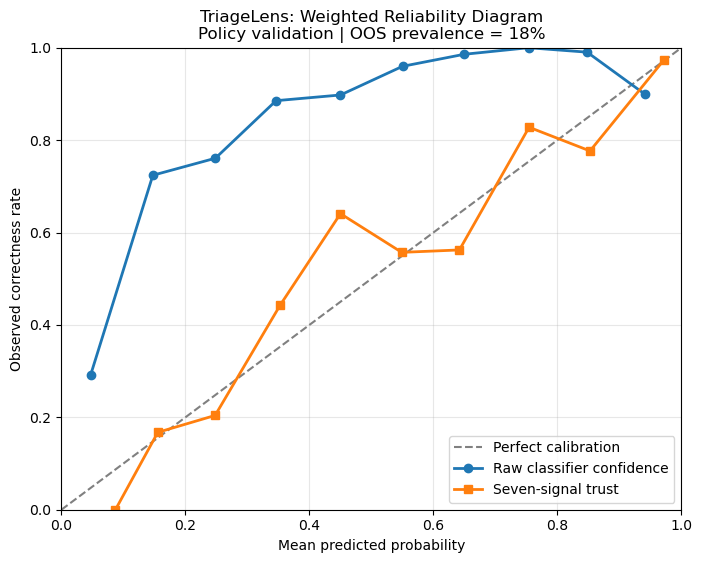

In [37]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# STEP 1: Prepare validation labels and weights
# --------------------------------------------------

y_calibration = policy_val_df[
    "is_correct"
].to_numpy(dtype=int)

weights_calibration = np.asarray(
    policy_weights,
    dtype=float
)

# --------------------------------------------------
# STEP 2: Define weighted calibration analysis
# --------------------------------------------------

def evaluate_calibration(
    scores,
    labels,
    weights,
    n_bins=10
):
    scores = np.asarray(scores, dtype=float)
    labels = np.asarray(labels, dtype=int)
    weights = np.asarray(weights, dtype=float)

    assert len(scores) == len(labels) == len(weights)
    assert np.all((scores >= 0) & (scores <= 1))
    assert np.all(weights > 0)

    # Weighted Brier score
    brier = np.average(
        (scores - labels) ** 2,
        weights=weights
    )

    # Ten equal-width confidence bins
    bin_edges = np.linspace(0, 1, n_bins + 1)

    bin_indices = np.digitize(
        scores,
        bin_edges[1:-1]
    )

    rows = []
    ece = 0.0

    for b in range(n_bins):

        mask = bin_indices == b

        if not mask.any():
            continue

        bin_weights = weights[mask]

        mean_score = np.average(
            scores[mask],
            weights=bin_weights
        )

        actual_accuracy = np.average(
            labels[mask],
            weights=bin_weights
        )

        weight_fraction = (
            bin_weights.sum() / weights.sum()
        )

        gap = abs(mean_score - actual_accuracy)

        ece += weight_fraction * gap

        rows.append({
            "Bin": (
                f"{bin_edges[b]:.1f}-"
                f"{bin_edges[b + 1]:.1f}"
            ),
            "Count": int(mask.sum()),
            "Weight fraction": weight_fraction,
            "Mean predicted": mean_score,
            "Observed correctness": actual_accuracy,
            "Calibration gap": gap
        })

    return brier, ece, pd.DataFrame(rows)


# --------------------------------------------------
# STEP 3: Evaluate both scoring methods
# --------------------------------------------------

conf_brier, conf_ece, conf_bins = evaluate_calibration(
    policy_val_df["confidence"],
    y_calibration,
    weights_calibration
)

trust_brier, trust_ece, trust_bins = evaluate_calibration(
    policy_val_df["trust_score"],
    y_calibration,
    weights_calibration
)

# --------------------------------------------------
# STEP 4: Display comparison
# --------------------------------------------------

calibration_comparison = pd.DataFrame({
    "Method": [
        "Raw classifier confidence",
        "Seven-signal trust"
    ],
    "Weighted Brier score": [
        conf_brier,
        trust_brier
    ],
    "Weighted ECE": [
        conf_ece,
        trust_ece
    ]
})

print("WEIGHTED CALIBRATION ANALYSIS")
print("=" * 50)

print("Policy-validation queries:", len(y_calibration))
print("Assumed OOS prevalence: 18%")

print("\nCalibration comparison:")

display(
    calibration_comparison.round(4)
)

print("\nSeven-signal trust calibration bins:")

display(
    trust_bins.round(4)
)

# --------------------------------------------------
# STEP 5: Plot reliability diagram
# --------------------------------------------------

plt.figure(figsize=(8, 6))

# Perfect calibration reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Perfect calibration"
)

plt.plot(
    conf_bins["Mean predicted"],
    conf_bins["Observed correctness"],
    marker="o",
    linewidth=2,
    label="Raw classifier confidence"
)

plt.plot(
    trust_bins["Mean predicted"],
    trust_bins["Observed correctness"],
    marker="s",
    linewidth=2,
    label="Seven-signal trust"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Observed correctness rate")

plt.title(
    "TriageLens: Weighted Reliability Diagram\n"
    "Policy validation | OOS prevalence = 18%"
)

plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.show()


In [38]:

import numpy as np
import pandas as pd

# ---------------------------------------------
# STEP 1: Prepare final test labels and weights
# ---------------------------------------------

y_test_cal = test_features[
    "is_correct"
].to_numpy(dtype=int)

test_cal_weights = np.asarray(
    test_weights,
    dtype=float
)

# ---------------------------------------------
# STEP 2: Evaluate frozen probability scores
# ---------------------------------------------

test_conf_brier, test_conf_ece, _ = (
    evaluate_calibration(
        test_features["confidence"],
        y_test_cal,
        test_cal_weights,
        n_bins=10
    )
)

test_trust_brier, test_trust_ece, _ = (
    evaluate_calibration(
        test_features["trust_score"],
        y_test_cal,
        test_cal_weights,
        n_bins=10
    )
)

# ---------------------------------------------
# STEP 3: Compare validation and test calibration
# ---------------------------------------------

calibration_summary = pd.DataFrame([
    {
        "Dataset": "Policy validation",
        "Method": "Raw confidence",
        "Brier": conf_brier,
        "ECE": conf_ece
    },
    {
        "Dataset": "Policy validation",
        "Method": "Seven-signal trust",
        "Brier": trust_brier,
        "ECE": trust_ece
    },
    {
        "Dataset": "Final test",
        "Method": "Raw confidence",
        "Brier": test_conf_brier,
        "ECE": test_conf_ece
    },
    {
        "Dataset": "Final test",
        "Method": "Seven-signal trust",
        "Brier": test_trust_brier,
        "ECE": test_trust_ece
    }
])

print("FINAL CALIBRATION AUDIT")
print("=" * 50)

display(calibration_summary.round(4))

# ---------------------------------------------
# STEP 4: Audit the frozen trust acceptance region
# ---------------------------------------------

accepted = (
    test_features["trust_score"].to_numpy()
    >= frozen_trust_threshold
)

accepted_mean_score = np.average(
    test_features["trust_score"].to_numpy()[accepted],
    weights=test_cal_weights[accepted]
)

accepted_actual_correctness = np.average(
    y_test_cal[accepted],
    weights=test_cal_weights[accepted]
)

calibration_gap = (
    accepted_mean_score - accepted_actual_correctness
)

print("\nFROZEN TRUST POLICY — ACCEPTED QUERIES")
print("-" * 50)

print(
    f"Frozen trust threshold: "
    f"{frozen_trust_threshold:.4f}"
)

print(
    f"Weighted mean predicted correctness: "
    f"{accepted_mean_score:.2%}"
)

print(
    f"Weighted observed correctness: "
    f"{accepted_actual_correctness:.2%}"
)

print(
    f"Calibration gap: "
    f"{calibration_gap * 100:+.2f} percentage points"
)

print(
    "\nPositive gap = overconfidence; "
    "negative gap = underconfidence."
)

print(
    "\nDiagnostic only: no model or threshold changes."
)


FINAL CALIBRATION AUDIT


,Dataset,Method,Brier,ECE
0,Policy validation,Raw confidence,0.2819,0.3694
1,Policy validation,Seven-signal trust,0.1197,0.0395
2,Final test,Raw confidence,0.2714,0.3643
3,Final test,Seven-signal trust,0.1076,0.0184



FROZEN TRUST POLICY — ACCEPTED QUERIES
--------------------------------------------------
Frozen trust threshold: 0.8855
Weighted mean predicted correctness: 96.83%
Weighted observed correctness: 96.96%
Calibration gap: -0.13 percentage points

Positive gap = overconfidence; negative gap = underconfidence.

Diagnostic only: no model or threshold changes.


In [39]:

from pathlib import Path
import pandas as pd
import json

# --------------------------------------------------
# STEP 1: Create research output directory
# --------------------------------------------------

RESULTS_DIR = Path("triagelens_results")

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# --------------------------------------------------
# STEP 2: Collect the completed experiment tables
# --------------------------------------------------

research_tables = {
    "final_test_results.csv": final_test_results,
    "bootstrap_confidence_intervals.csv": bootstrap_summary,
    "feature_ablation.csv": ablation_df,
    "calibration_results.csv": calibration_summary,
    "cost_sensitivity.csv": sensitivity_df
}

# --------------------------------------------------
# STEP 3: Export tables without rounding away values
# --------------------------------------------------

for filename, dataframe in research_tables.items():

    output_path = RESULTS_DIR / filename

    dataframe.to_csv(
        output_path,
        index=False,
        float_format="%.8f"
    )

    print("Saved:", output_path)

# --------------------------------------------------
# STEP 4: Record the experimental configuration
# --------------------------------------------------

experiment_config = {
    "project": "TriageLens",
    "dataset": "CLINC150",
    "primary_classifier": "TF-IDF + Logistic Regression",
    "secondary_classifier": "LSA + Logistic Regression",
    "trust_model": "StandardScaler + Logistic Regression",
    "number_of_reliability_signals": len(FEATURE_COLUMNS),
    "feature_columns": FEATURE_COLUMNS,
    "known_test_queries": 4500,
    "oos_test_queries": 1000,
    "assumed_oos_prevalence": 0.18,
    "wrong_automation_cost": 10.0,
    "human_review_cost": 1.0,
    "confidence_threshold": float(
        frozen_confidence_threshold
    ),
    "trust_threshold": float(
        frozen_trust_threshold
    ),
    "bootstrap_repetitions": 3000,
    "random_seed": 42,
    "threshold_selection": "Policy validation only",
    "final_test_policy": "Frozen thresholds; no test refitting",
    "relative_test_cost_savings_percent": float(
        relative_cost_savings
    )
}

config_path = RESULTS_DIR / "experiment_config.json"

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(
        experiment_config,
        f,
        indent=4
    )

print("Saved:", config_path)

# --------------------------------------------------
# STEP 5: Verify exported files
# --------------------------------------------------

print("\nRESEARCH EXPORT SUMMARY")
print("-" * 50)

saved_files = list(RESULTS_DIR.iterdir())

print("Total files saved:", len(saved_files))
print("Output directory:", RESULTS_DIR.resolve())

for file in sorted(saved_files):
    print("-", file.name)

print("\nResearch results exported successfully!")


Saved: triagelens_results\final_test_results.csv
Saved: triagelens_results\bootstrap_confidence_intervals.csv
Saved: triagelens_results\feature_ablation.csv
Saved: triagelens_results\calibration_results.csv
Saved: triagelens_results\cost_sensitivity.csv
Saved: triagelens_results\experiment_config.json

RESEARCH EXPORT SUMMARY
--------------------------------------------------
Total files saved: 6
Output directory: triagelens_results
- bootstrap_confidence_intervals.csv
- calibration_results.csv
- cost_sensitivity.csv
- experiment_config.json
- feature_ablation.csv
- final_test_results.csv

Research results exported successfully!


In [40]:

import joblib
from pathlib import Path

# ---------------------------------------------
# STEP 1: Create model directory
# ---------------------------------------------

MODEL_DIR = Path("triagelens_models")

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ---------------------------------------------
# STEP 2: Collect trained components
# ---------------------------------------------

trained_components = {
    "tfidf_vectorizer.joblib": tfidf,
    "primary_classifier.joblib": baseline_model,
    "lsa_transformer.joblib": lsa_model,
    "lsa_classifier.joblib": lsa_classifier,
    "trust_model.joblib": trust_model,

    # Reference representations for nearest-neighbor
    # reliability signals
    "training_tfidf.joblib": X_train,
    "training_lsa.joblib": X_train_lsa,
    "training_labels.joblib": y_train.to_numpy(),

    # Exact feature order used by the trust model
    "feature_columns.joblib": FEATURE_COLUMNS
}

# ---------------------------------------------
# STEP 3: Save each component
# ---------------------------------------------

for filename, component in trained_components.items():

    output_path = MODEL_DIR / filename

    joblib.dump(
        component,
        output_path,
        compress=3
    )

    print("Saved:", filename)

# ---------------------------------------------
# STEP 4: Verify saved files
# ---------------------------------------------

saved_models = sorted(
    MODEL_DIR.glob("*.joblib")
)

print("\nMODEL EXPORT SUMMARY")
print("-" * 50)

print("Total model files:", len(saved_models))
print("Model directory:", MODEL_DIR.resolve())

for file in saved_models:
    print("-", file.name)

print("\nAll trained models saved successfully!")


Saved: tfidf_vectorizer.joblib
Saved: primary_classifier.joblib
Saved: lsa_transformer.joblib
Saved: lsa_classifier.joblib
Saved: trust_model.joblib
Saved: training_tfidf.joblib
Saved: training_lsa.joblib
Saved: training_labels.joblib
Saved: feature_columns.joblib

MODEL EXPORT SUMMARY
--------------------------------------------------
Total model files: 9
Model directory: triagelens_models
- feature_columns.joblib
- lsa_classifier.joblib
- lsa_transformer.joblib
- primary_classifier.joblib
- tfidf_vectorizer.joblib
- training_labels.joblib
- training_lsa.joblib
- training_tfidf.joblib
- trust_model.joblib

All trained models saved successfully!


In [41]:

import joblib
import numpy as np
from pathlib import Path

# ---------------------------------------
# STEP 1: Locate saved models
# ---------------------------------------

MODEL_DIR = Path("triagelens_models")

model_files = {
    "tfidf": "tfidf_vectorizer.joblib",
    "primary": "primary_classifier.joblib",
    "lsa": "lsa_transformer.joblib",
    "lsa_classifier": "lsa_classifier.joblib",
    "trust": "trust_model.joblib",
    "training_tfidf": "training_tfidf.joblib",
    "training_lsa": "training_lsa.joblib",
    "training_labels": "training_labels.joblib",
    "features": "feature_columns.joblib"
}

# ---------------------------------------
# STEP 2: Load saved components
# ---------------------------------------

loaded_models = {}

for name, filename in model_files.items():

    file_path = MODEL_DIR / filename

    loaded_models[name] = joblib.load(file_path)

    print("Loaded:", filename)

# ---------------------------------------
# STEP 3: Select sample test queries
# ---------------------------------------

sample = test_features.head(10).copy()

sample_texts = sample["text"]

# ---------------------------------------
# STEP 4: Verify primary classifier
# ---------------------------------------

X_sample = loaded_models["tfidf"].transform(
    sample_texts
)

reloaded_predictions = (
    loaded_models["primary"].predict(X_sample)
)

prediction_match = np.array_equal(
    reloaded_predictions,
    sample["predicted_intent"].to_numpy()
)

# ---------------------------------------
# STEP 5: Verify trust model
# ---------------------------------------

saved_features = loaded_models["features"]

assert saved_features == FEATURE_COLUMNS

reloaded_trust_scores = (
    loaded_models["trust"].predict_proba(
        sample[saved_features]
    )[:, 1]
)

trust_scores_match = np.allclose(
    reloaded_trust_scores,
    sample["trust_score"].to_numpy(),
    atol=1e-10
)

# ---------------------------------------
# STEP 6: Verify reference data
# ---------------------------------------

training_data_valid = (
    loaded_models["training_tfidf"].shape[0] == 15000
    and loaded_models["training_lsa"].shape == (15000, 300)
    and len(loaded_models["training_labels"]) == 15000
)

# ---------------------------------------
# STEP 7: Display verification results
# ---------------------------------------

print("\nMODEL RELOAD VERIFICATION")
print("-" * 50)

print("Total components loaded:", len(loaded_models))

print("Primary predictions match:", prediction_match)

print("Trust scores match:", trust_scores_match)

print("Training reference data valid:", training_data_valid)

if (
    prediction_match
    and trust_scores_match
    and training_data_valid
):
    print("\nSUCCESS: Saved models verified!")
else:
    print("\nWARNING: Model verification failed.")


Loaded: tfidf_vectorizer.joblib
Loaded: primary_classifier.joblib
Loaded: lsa_transformer.joblib
Loaded: lsa_classifier.joblib
Loaded: trust_model.joblib
Loaded: training_tfidf.joblib
Loaded: training_lsa.joblib
Loaded: training_labels.joblib
Loaded: feature_columns.joblib

MODEL RELOAD VERIFICATION
--------------------------------------------------
Total components loaded: 9
Primary predictions match: True
Trust scores match: True
Training reference data valid: True

SUCCESS: Saved models verified!


In [42]:

import sys
import json
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError

# --------------------------------------------------
# STEP 1: Define the libraries used in TriageLens
# --------------------------------------------------

packages = [
    "numpy",
    "pandas",
    "scipy",
    "scikit-learn",
    "matplotlib",
    "joblib",
    "jupyter",
    "ipykernel",
    "torch",
    "transformers",
    "sentence-transformers",
    "streamlit"
]

# --------------------------------------------------
# STEP 2: Collect package versions
# --------------------------------------------------

package_versions = {}

for package in packages:

    try:
        package_versions[package] = version(package)

    except PackageNotFoundError:
        package_versions[package] = None

# --------------------------------------------------
# STEP 3: Save environment information
# --------------------------------------------------

RESULTS_DIR = Path("triagelens_results")
RESULTS_DIR.mkdir(exist_ok=True)

environment_info = {
    "python_version": sys.version,
    "python_executable": sys.executable,
    "package_versions": package_versions
}

environment_path = (
    RESULTS_DIR / "environment_versions.json"
)

with open(environment_path, "w", encoding="utf-8") as f:
    json.dump(environment_info, f, indent=4)

# --------------------------------------------------
# STEP 4: Create requirements.txt
# --------------------------------------------------

requirements_path = RESULTS_DIR / "requirements.txt"

with open(requirements_path, "w", encoding="utf-8") as f:

    for package, package_version in package_versions.items():

        if package_version is not None:
            f.write(f"{package}=={package_version}\n")

# --------------------------------------------------
# STEP 5: Display environment summary
# --------------------------------------------------

print("TRIAGELENS ENVIRONMENT RECORD")
print("=" * 50)

print("Python version:", sys.version.split()[0])

print("\nInstalled package versions:")

for package, package_version in package_versions.items():
    print(
        f"{package:22s}: "
        f"{package_version or 'Not installed'}"
    )

print("\nFiles saved:")
print("-", environment_path.resolve())
print("-", requirements_path.resolve())

print("\nEnvironment information saved successfully!")


TRIAGELENS ENVIRONMENT RECORD
Python version: 3.12.7

Installed package versions:
numpy                 : 1.26.4
pandas                : 2.2.2
scipy                 : 1.13.1
scikit-learn          : 1.5.1
matplotlib            : 3.9.2
joblib                : 1.4.2
jupyter               : 1.0.0
ipykernel             : 6.28.0
torch                 : 2.14.1
transformers          : 5.21.0
sentence-transformers : 6.2.0
streamlit             : 1.37.1

Files saved:
- triagelens_results/environment_versions.json
- triagelens_results/requirements.txt

Environment information saved successfully!


In [43]:

import numpy as np
import pandas as pd
import json

from pathlib import Path
from scipy import sparse
from scipy.spatial.distance import jensenshannon
from sklearn.preprocessing import normalize

# ----------------------------------------------
# STEP 1: Load frozen decision thresholds
# ----------------------------------------------

config_path = (
    Path("triagelens_results")
    / "experiment_config.json"
)

with open(config_path, "r", encoding="utf-8") as f:
    config = json.load(f)

CONFIDENCE_THRESHOLD = config["confidence_threshold"]
TRUST_THRESHOLD = config["trust_threshold"]


# ----------------------------------------------
# STEP 2: Reusable nearest-neighbor function
# ----------------------------------------------

def get_knn_signals(
    query_vector,
    training_vectors,
    training_labels,
    k=5
):
    similarities = query_vector @ training_vectors.T

    if sparse.issparse(similarities):
        similarities = similarities.toarray()

    similarities = np.asarray(similarities).ravel()

    top_indices = np.argpartition(
        -similarities,
        kth=k - 1
    )[:k]

    votes = {}

    for index in top_indices:
        intent = training_labels[index]
        weight = max(float(similarities[index]), 0.0)

        votes[intent] = votes.get(intent, 0.0) + weight

    total_weight = sum(votes.values())

    if total_weight > 0:
        majority_intent = max(votes, key=votes.get)
        agreement = votes[majority_intent] / total_weight
    else:
        majority_intent = None
        agreement = 0.0

    return (
        float(similarities.max()),
        float(agreement),
        majority_intent
    )


# ----------------------------------------------
# STEP 3: Define the complete inference pipeline
# ----------------------------------------------

def predict_triagelens(query):

    if not isinstance(query, str) or not query.strip():
        raise ValueError("Please enter a non-empty query.")

    # Transform new query using saved models
    X_query = loaded_models["tfidf"].transform([query])

    X_query_lsa = normalize(
        loaded_models["lsa"].transform(X_query)
    )

    # Primary classifier probabilities
    primary = loaded_models["primary"]

    probabilities = primary.predict_proba(X_query)[0]

    predicted_intent = primary.classes_[
        np.argmax(probabilities)
    ]

    confidence = float(probabilities.max())

    # Second classifier probabilities
    lsa_classifier = loaded_models["lsa_classifier"]

    assert np.array_equal(
        primary.classes_,
        lsa_classifier.classes_
    )

    lsa_probabilities = (
        lsa_classifier.predict_proba(X_query_lsa)[0]
    )

    # TF-IDF neighbor signals
    tfidf_nn, tfidf_knn, _ = get_knn_signals(
        X_query,
        loaded_models["training_tfidf"],
        loaded_models["training_labels"]
    )

    # LSA neighbor signals
    lsa_nn, lsa_knn, lsa_majority = get_knn_signals(
        X_query_lsa,
        loaded_models["training_lsa"],
        loaded_models["training_labels"]
    )

    # Model distribution agreement
    model_agreement = -float(
        jensenshannon(
            probabilities,
            lsa_probabilities
        )
    )

    # Primary classifier / LSA kNN match
    knn_match = int(
        predicted_intent == lsa_majority
    )

    # Assemble the seven features
    feature_values = {
        "confidence": confidence,
        "tfidf_nn_similarity": tfidf_nn,
        "knn_agreement": tfidf_knn,
        "lsa_nn_similarity": lsa_nn,
        "lsa_knn_agreement": lsa_knn,
        "model_agreement_score": model_agreement,
        "classifier_lsa_knn_match": knn_match
    }

    feature_df = pd.DataFrame([feature_values])

    feature_df = feature_df[
        loaded_models["features"]
    ]

    # Predict using the saved trust model
    trust_score = float(
        loaded_models["trust"].predict_proba(
            feature_df
        )[0, 1]
    )

    # Compare the two frozen decision policies
    confidence_decision = (
        "AUTOMATE"
        if confidence >= CONFIDENCE_THRESHOLD
        else "HUMAN REVIEW"
    )

    trust_decision = (
        "AUTOMATE"
        if trust_score >= TRUST_THRESHOLD
        else "HUMAN REVIEW"
    )

    return {
        "query": query,
        "predicted_intent": predicted_intent,
        "confidence": confidence,
        "trust_score": trust_score,
        "confidence_decision": confidence_decision,
        "triagelens_decision": trust_decision,
        "signals": feature_values
    }


# ----------------------------------------------
# STEP 4: Test with a new query
# ----------------------------------------------

sample_query = (
    "How can I change the PIN on my debit card?"
)

result = predict_triagelens(sample_query)

print("TRIAGELENS INFERENCE RESULT")
print("=" * 50)

print("Query:", result["query"])
print("Predicted intent:", result["predicted_intent"])

print(
    f"Classifier confidence: "
    f"{result['confidence']:.4f}"
)

print(
    f"Learned trust score: "
    f"{result['trust_score']:.4f}"
)

print(
    "Confidence-only decision:",
    result["confidence_decision"]
)

print(
    "TriageLens decision:",
    result["triagelens_decision"]
)

print("\nSEVEN RELIABILITY SIGNALS")
print("-" * 50)

for name, value in result["signals"].items():
    print(f"{name:32s}: {value:.4f}")


TRIAGELENS INFERENCE RESULT
Query: How can I change the PIN on my debit card?
Predicted intent: pin_change
Classifier confidence: 0.2960
Learned trust score: 0.8877
Confidence-only decision: HUMAN REVIEW
TriageLens decision: AUTOMATE

SEVEN RELIABILITY SIGNALS
--------------------------------------------------
confidence                      : 0.2960
tfidf_nn_similarity             : 0.4474
knn_agreement                   : 0.7961
lsa_nn_similarity               : 0.7750
lsa_knn_agreement               : 1.0000
model_agreement_score           : -0.2595
classifier_lsa_knn_match        : 1.0000


In [44]:

import pandas as pd

# --------------------------------------------
# STEP 1: Ask the user to enter a query
# --------------------------------------------

user_query = input(
    "Enter your query for TriageLens: "
).strip()

# --------------------------------------------
# STEP 2: Validate the input
# --------------------------------------------

if not user_query:
    print("Please enter a non-empty query.")

else:
    # ----------------------------------------
    # STEP 3: Run the trained inference system
    # ----------------------------------------

    result = predict_triagelens(user_query)

    print("\nTRIAGELENS INTERACTIVE PREDICTION")
    print("=" * 55)

    print("Query:", result["query"])
    print("Predicted intent:", result["predicted_intent"])

    print(
        f"\nClassifier confidence: "
        f"{result['confidence']:.4f}"
    )

    print(
        f"Learned trust score: "
        f"{result['trust_score']:.4f}"
    )

    print("\nDECISION COMPARISON")
    print("-" * 55)

    print(
        "Confidence-only:",
        result["confidence_decision"]
    )

    print(
        "TriageLens:",
        result["triagelens_decision"]
    )

    # ----------------------------------------
    # STEP 4: Check distance from threshold
    # ----------------------------------------

    trust_margin = (
        result["trust_score"] - TRUST_THRESHOLD
    )

    print(
        f"\nTrust threshold margin: "
        f"{trust_margin:+.4f}"
    )

    if abs(trust_margin) < 0.02:
        print(
            "NOTE: Trust score is close to "
            "the automation threshold."
        )

    # ----------------------------------------
    # STEP 5: Display seven reliability signals
    # ----------------------------------------

    signal_table = pd.DataFrame(
        [
            {
                "Reliability signal": name,
                "Value": value
            }
            for name, value in result["signals"].items()
        ]
    )

    print("\nSEVEN RELIABILITY SIGNALS")
    print("-" * 55)

    display(
        signal_table.style.format({
            "Value": "{:.4f}"
        })
    )


Enter your query for TriageLens:  I need to report my stolen credit card



TRIAGELENS INTERACTIVE PREDICTION
Query: I need to report my stolen credit card
Predicted intent: report_lost_card

Classifier confidence: 0.7056
Learned trust score: 0.9894

DECISION COMPARISON
-------------------------------------------------------
Confidence-only: AUTOMATE
TriageLens: AUTOMATE

Trust threshold margin: +0.1038

SEVEN RELIABILITY SIGNALS
-------------------------------------------------------


,Reliability signal,Value
0,confidence,0.7056
1,tfidf_nn_similarity,0.7561
2,knn_agreement,1.0000
3,lsa_nn_similarity,0.9270
4,lsa_knn_agreement,0.6062
5,model_agreement_score,-0.1900
6,classifier_lsa_knn_match,1.0000


In [45]:

%%writefile triagelens_inference.py

import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

from scipy import sparse
from scipy.spatial.distance import jensenshannon
from sklearn.preprocessing import normalize


class TriageLensPredictor:
    """
    Reusable inference pipeline for TriageLens.

    Loads trained models and applies the frozen
    confidence-only and seven-signal trust policies.
    """

    def __init__(self, project_dir=None):

        if project_dir is None:
            self.project_dir = Path(__file__).resolve().parent
        else:
            self.project_dir = Path(project_dir).resolve()

        model_dir = self.project_dir / "triagelens_models"

        config_path = (
            self.project_dir
            / "triagelens_results"
            / "experiment_config.json"
        )

        with open(config_path, "r", encoding="utf-8") as f:
            config = json.load(f)

        self.confidence_threshold = float(
            config["confidence_threshold"]
        )

        self.trust_threshold = float(
            config["trust_threshold"]
        )

        # Load all trained components
        self.tfidf = joblib.load(
            model_dir / "tfidf_vectorizer.joblib"
        )

        self.primary = joblib.load(
            model_dir / "primary_classifier.joblib"
        )

        self.lsa = joblib.load(
            model_dir / "lsa_transformer.joblib"
        )

        self.lsa_classifier = joblib.load(
            model_dir / "lsa_classifier.joblib"
        )

        self.trust_model = joblib.load(
            model_dir / "trust_model.joblib"
        )

        self.training_tfidf = joblib.load(
            model_dir / "training_tfidf.joblib"
        )

        self.training_lsa = joblib.load(
            model_dir / "training_lsa.joblib"
        )

        self.training_labels = np.asarray(
            joblib.load(
                model_dir / "training_labels.joblib"
            )
        )

        self.feature_columns = joblib.load(
            model_dir / "feature_columns.joblib"
        )

        # Ensure probability columns refer to the same intents
        if not np.array_equal(
            self.primary.classes_,
            self.lsa_classifier.classes_
        ):
            raise ValueError("Classifier class orders differ.")

        print("TriageLens models loaded successfully!")

    def _knn_signals(self, query_vector, training_vectors, k=5):

        similarities = query_vector @ training_vectors.T

        if sparse.issparse(similarities):
            similarities = similarities.toarray()

        similarities = np.asarray(similarities).ravel()

        top_indices = np.argpartition(
            -similarities,
            kth=k - 1
        )[:k]

        votes = {}

        for idx in top_indices:

            intent = self.training_labels[idx]
            weight = max(float(similarities[idx]), 0.0)

            votes[intent] = votes.get(intent, 0.0) + weight

        total_weight = sum(votes.values())

        if total_weight > 0:

            majority_intent = max(votes, key=votes.get)

            agreement = (
                votes[majority_intent] / total_weight
            )

        else:
            majority_intent = None
            agreement = 0.0

        return (
            float(similarities.max()),
            float(agreement),
            majority_intent
        )

    def predict(self, query):

        if not isinstance(query, str) or not query.strip():
            raise ValueError("Query must be non-empty text.")

        # Generate TF-IDF and LSA representations
        X_query = self.tfidf.transform([query])

        X_query_lsa = normalize(
            self.lsa.transform(X_query)
        )

        # Primary classifier
        probabilities = self.primary.predict_proba(
            X_query
        )[0]

        predicted_intent = self.primary.classes_[
            np.argmax(probabilities)
        ]

        confidence = float(probabilities.max())

        # Secondary classifier
        lsa_probabilities = (
            self.lsa_classifier.predict_proba(
                X_query_lsa
            )[0]
        )

        # TF-IDF neighbor features
        tfidf_nn, tfidf_knn, _ = self._knn_signals(
            X_query,
            self.training_tfidf
        )

        # LSA neighbor features
        lsa_nn, lsa_knn, lsa_majority = self._knn_signals(
            X_query_lsa,
            self.training_lsa
        )

        # Model agreement
        model_agreement = -float(
            jensenshannon(
                probabilities,
                lsa_probabilities
            )
        )

        # Classifier-neighbor match
        knn_match = int(
            predicted_intent == lsa_majority
        )

        # Assemble all seven features
        signals = {
            "confidence": confidence,
            "tfidf_nn_similarity": tfidf_nn,
            "knn_agreement": tfidf_knn,
            "lsa_nn_similarity": lsa_nn,
            "lsa_knn_agreement": lsa_knn,
            "model_agreement_score": model_agreement,
            "classifier_lsa_knn_match": knn_match
        }

        feature_df = pd.DataFrame(
            [signals],
            columns=self.feature_columns
        )

        # Learned trust score
        trust_score = float(
            self.trust_model.predict_proba(
                feature_df
            )[0, 1]
        )

        # Apply frozen policies
        confidence_decision = (
            "AUTOMATE"
            if confidence >= self.confidence_threshold
            else "HUMAN REVIEW"
        )

        triagelens_decision = (
            "AUTOMATE"
            if trust_score >= self.trust_threshold
            else "HUMAN REVIEW"
        )

        return {
            "query": query,
            "predicted_intent": str(predicted_intent),
            "confidence": confidence,
            "trust_score": trust_score,
            "confidence_decision": confidence_decision,
            "triagelens_decision": triagelens_decision,
            "signals": signals
        }


Writing triagelens_inference.py


In [46]:

import numpy as np

from triagelens_inference import TriageLensPredictor

# -----------------------------------------
# STEP 1: Load our saved TriageLens system
# -----------------------------------------

predictor = TriageLensPredictor()

# -----------------------------------------
# STEP 2: Define sample queries
# -----------------------------------------

test_queries = [
    "How can I change the PIN on my debit card?",
    "I need to report my stolen credit card",
    "Please cancel my flight reservation"
]

# -----------------------------------------
# STEP 3: Compare notebook and module results
# -----------------------------------------

print("\nTRIAGELENS MODULE VERIFICATION")
print("=" * 55)

all_tests_passed = True

for query in test_queries:

    # Original notebook implementation
    notebook_result = predict_triagelens(query)

    # New reusable Python module
    module_result = predictor.predict(query)

    # Compare predicted intent
    intent_match = (
        notebook_result["predicted_intent"]
        == module_result["predicted_intent"]
    )

    # Compare classifier confidence
    confidence_match = np.isclose(
        notebook_result["confidence"],
        module_result["confidence"],
        atol=1e-10
    )

    # Compare trust score
    trust_match = np.isclose(
        notebook_result["trust_score"],
        module_result["trust_score"],
        atol=1e-10
    )

    # Compare all seven features
    signals_match = all(
        np.isclose(
            notebook_result["signals"][feature],
            module_result["signals"][feature],
            atol=1e-10
        )
        for feature in FEATURE_COLUMNS
    )

    # Compare automation decisions
    decision_match = (
        notebook_result["triagelens_decision"]
        == module_result["triagelens_decision"]
        and
        notebook_result["confidence_decision"]
        == module_result["confidence_decision"]
    )

    test_passed = all([
        intent_match,
        confidence_match,
        trust_match,
        signals_match,
        decision_match
    ])

    all_tests_passed &= test_passed

    print("\nQuery:", query)
    print("Predicted intent:", module_result["predicted_intent"])

    print(
        "Classifier confidence:",
        round(module_result["confidence"], 4)
    )

    print(
        "Trust score:",
        round(module_result["trust_score"], 4)
    )

    print(
        "TriageLens decision:",
        module_result["triagelens_decision"]
    )

    print("All seven signals match:", signals_match)
    print("Verification passed:", test_passed)

# -----------------------------------------
# STEP 4: Final verification
# -----------------------------------------

print("\nFINAL VERIFICATION")
print("=" * 55)

if all_tests_passed:
    print("SUCCESS: All predictions and scores match!")
    print("TriageLens inference module is verified.")
else:
    print("WARNING: Some results do not match.")
    print("Check the differences before building the app.")


TriageLens models loaded successfully!

TRIAGELENS MODULE VERIFICATION

Query: How can I change the PIN on my debit card?
Predicted intent: pin_change
Classifier confidence: 0.296
Trust score: 0.8877
TriageLens decision: AUTOMATE
All seven signals match: True
Verification passed: True

Query: I need to report my stolen credit card
Predicted intent: report_lost_card
Classifier confidence: 0.7056
Trust score: 0.9894
TriageLens decision: AUTOMATE
All seven signals match: True
Verification passed: True

Query: Please cancel my flight reservation
Predicted intent: cancel_reservation
Classifier confidence: 0.5946
Trust score: 0.9785
TriageLens decision: AUTOMATE
All seven signals match: True
Verification passed: True

FINAL VERIFICATION
SUCCESS: All predictions and scores match!
TriageLens inference module is verified.


In [47]:

%%writefile triagelens_app.py

import streamlit as st
import pandas as pd

from triagelens_inference import TriageLensPredictor


# --------------------------------------------------
# STEP 1: Configure application
# --------------------------------------------------

st.set_page_config(
    page_title="TriageLens",
    page_icon="🛡️",
    layout="wide"
)


# --------------------------------------------------
# STEP 2: Load saved models once
# --------------------------------------------------

@st.cache_resource
def load_predictor():
    return TriageLensPredictor()


try:
    predictor = load_predictor()
except Exception as error:
    st.error(f"Unable to load TriageLens models: {error}")
    st.stop()


# --------------------------------------------------
# STEP 3: Application header
# --------------------------------------------------

st.title("🛡️ TriageLens")

st.subheader(
    "Confidence-Aware Human-in-the-Loop "
    "Intent Classification"
)

st.caption(
    "A master's research prototype using seven "
    "reliability signals to support automation decisions."
)

st.divider()


# --------------------------------------------------
# STEP 4: Sidebar — Research information
# --------------------------------------------------

with st.sidebar:

    st.header("About TriageLens")

    st.write(
        "TriageLens predicts user intents and estimates "
        "whether a prediction is reliable enough "
        "for automatic classification."
    )

    st.subheader("Frozen Policy Thresholds")

    st.metric(
        "Confidence threshold",
        f"{predictor.confidence_threshold:.2%}"
    )

    st.metric(
        "Trust threshold",
        f"{predictor.trust_threshold:.2%}"
    )

    st.divider()

    st.subheader("Research Configuration")

    st.write("**Dataset:** CLINC150")
    st.write("**Known intents:** 150")
    st.write("**Reliability signals:** 7")
    st.write("**Assumed OOS prevalence:** 18%")
    st.write("**Wrong automation / review cost:** 10:1")

    st.info(
        "This is a research demonstration. "
        "AUTOMATE means accepting the predicted intent, "
        "not executing a real banking or other action."
    )


# --------------------------------------------------
# STEP 5: User query input
# --------------------------------------------------

st.header("Analyze a User Query")

with st.form("query_form"):

    user_query = st.text_area(
        "Enter your query",
        value="I need to report my stolen credit card",
        height=100,
        placeholder="Type a sentence here..."
    )

    analyze_button = st.form_submit_button(
        "Analyze Query",
        type="primary",
        use_container_width=True
    )


# --------------------------------------------------
# STEP 6: Run inference
# --------------------------------------------------

if analyze_button:

    if not user_query.strip():

        st.warning("Please enter a query.")

    else:

        with st.spinner("Analyzing query..."):

            try:
                result = predictor.predict(user_query)
            except Exception as error:
                st.error(f"Prediction failed: {error}")
                st.stop()

        st.divider()

        # ------------------------------------------
        # Predicted intent
        # ------------------------------------------

        st.header("Prediction Results")

        st.write("**Predicted intent:**")
        st.code(result["predicted_intent"])

        # ------------------------------------------
        # Confidence and trust scores
        # ------------------------------------------

        col1, col2 = st.columns(2)

        with col1:
            st.metric(
                "Classifier Confidence",
                f"{result['confidence']:.2%}"
            )

            st.progress(
                float(result["confidence"])
            )

        with col2:
            st.metric(
                "Learned Trust Score",
                f"{result['trust_score']:.2%}"
            )

            st.progress(
                float(result["trust_score"])
            )

        # ------------------------------------------
        # Decision comparison
        # ------------------------------------------

        st.subheader("Automation Decisions")

        col3, col4 = st.columns(2)

        with col3:
            st.write("**Confidence-Only Policy**")

            st.info(
                result["confidence_decision"]
            )

        with col4:
            st.write("**Seven-Signal TriageLens**")

            if result["triagelens_decision"] == "AUTOMATE":

                st.success(
                    "AUTOMATE — Accept intent classification"
                )

            else:

                st.warning(
                    "HUMAN REVIEW — Escalate query"
                )

        # ------------------------------------------
        # Threshold margin
        # ------------------------------------------

        trust_margin = (
            result["trust_score"]
            - predictor.trust_threshold
        )

        st.write(
            f"**Trust threshold margin:** "
            f"{trust_margin:+.4f}"
        )

        if abs(trust_margin) < 0.02:

            st.warning(
                "This decision is close to the "
                "automation threshold."
            )

        # ------------------------------------------
        # Seven reliability signals
        # ------------------------------------------

        st.divider()

        st.subheader("Seven Reliability Signals")

        signals_df = pd.DataFrame([
            {
                "Signal": signal,
                "Value": round(float(value), 4)
            }
            for signal, value in result["signals"].items()
        ])

        st.dataframe(
            signals_df,
            use_container_width=True,
            hide_index=True
        )

        with st.expander("Understanding the Signals"):

            st.write(
                "**Confidence:** Primary classifier's "
                "maximum class probability."
            )

            st.write(
                "**TF-IDF similarity:** Similarity to "
                "the closest training query."
            )

            st.write(
                "**TF-IDF kNN agreement:** Weighted "
                "consensus among five lexical neighbors."
            )

            st.write(
                "**LSA similarity:** Similarity to the "
                "closest training query in LSA space."
            )

            st.write(
                "**LSA kNN agreement:** Weighted "
                "consensus among five LSA neighbors."
            )

            st.write(
                "**Model agreement:** Negative "
                "Jensen-Shannon distance. Values "
                "closer to zero mean greater agreement."
            )

            st.write(
                "**Classifier-LSA kNN match:** "
                "1 means both select the same intent; "
                "0 means they disagree."
            )

        st.caption(
            "Trust scores are statistical estimates, "
            "not guarantees. Human review does not "
            "necessarily imply that a query is OOS."
        )


# --------------------------------------------------
# STEP 7: Footer
# --------------------------------------------------

st.divider()

st.caption(
    "TriageLens | Master's Research Prototype | "
    "CLINC150 | Frozen Seven-Signal Trust Model"
)


Writing triagelens_app.py


In [48]:

import sys

print("Jupyter Python version:", sys.version.split()[0])
print("Jupyter Python executable:", sys.executable)


Jupyter Python version: 3.12.7
Jupyter Python executable: python.exe
